# Stage 1 – AI Governance: Data Preparation, Analysis and Knowledge Graph Construction

## Introduction

This notebook presents the first stage of the CTL project, focusing on the analysis of a large-scale media dataset within the topic area of **AI Governance**.

The objective is to transform the raw dataset into a structured and reliable basis for further analysis and knowledge graph construction. The workflow includes systematic data inspection, cleaning and preprocessing, followed by exploratory analysis of relevant patterns, sources, topics and developments within the dataset.

The resulting cleaned and structured data will serve as the foundation for the identification of relevant entities and relationships and the subsequent construction of an AI Governance-focused knowledge graph.

## 1. Data Loading and Initial Inspection

The first step is to load the raw media dataset and examine its basic structure.  
Before applying any transformations, the dataset is inspected for its dimensions, available variables, data types, and general consistency.

In [49]:
from pathlib import Path
import pandas as pd
import ast

In [50]:
current_path = Path.cwd()

PROJECT_ROOT = next(
    path for path in [current_path, *current_path.parents]
    if (path / ".git").exists()
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai_media_dataset_20260911.csv"

In [51]:
path_summary = pd.DataFrame({
    "Item": [
        "Current working directory",
        "Project root",
        "Dataset path",
        "Dataset found"
    ],
    "Value": [
        str(current_path),
        str(PROJECT_ROOT),
        str(DATA_PATH),
        str(DATA_PATH.exists())
    ]
})

path_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Item", "Value"], **{"text-align": "left"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Item,Value
Current working directory,C:\Users\dana1\Documents\CTL\notebooks\stage1_ai_governance
Project root,C:\Users\dana1\Documents\CTL
Dataset path,C:\Users\dana1\Documents\CTL\data\raw\ai_media_dataset_20260911.csv
Dataset found,True


In [52]:
df = pd.read_csv(DATA_PATH)

In [53]:
dataset_overview = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of columns"
    ],
    "Result": [
        len(df),
        df.shape[1]
    ]
})

dataset_overview.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Number of records,47751
Number of columns,7


In [54]:
column_overview = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

column_overview.style \
    .hide(axis="index") \
    .set_properties(subset=["Column", "Data Type"], **{"text-align": "left"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Column,Data Type
Unnamed: 0,int64
title,str
date,str
content,str
domain,str
url,str
tags,str


The raw dataset contains 47,751 records and 7 columns. The variables include an identifier-like field, article metadata, textual content, source domain, URL, and topic tags.

## 2. Data Quality Assessment

Before cleaning the dataset, the main data-quality dimensions are assessed.  
This includes missing values, identifier uniqueness, duplicate records, date consistency, and the structure of the `content` and `tags` fields.

In [55]:
quality_summary = pd.DataFrame({
    "Quality Check": [
        "Records",
        "Columns",
        "Missing values",
        "Duplicate IDs",
        "Duplicate URLs",
        "Duplicate titles",
        "Duplicate title-domain combinations",
        "Duplicate content"
    ],
    "Result": [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df["Unnamed: 0"].duplicated().sum()),
        int(df["url"].duplicated().sum()),
        int(df["title"].duplicated().sum()),
        int(df.duplicated(subset=["title", "domain"]).sum()),
        int(df["content"].duplicated().sum())
    ]
})

quality_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Quality Check"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Quality Check,Result
Records,47751
Columns,7
Missing values,0
Duplicate IDs,0
Duplicate URLs,0
Duplicate titles,0
Duplicate title-domain combinations,0
Duplicate content,66


### Initial Findings

The dataset contains 47,751 records with no missing values in any column.

No duplicate identifiers, URLs, titles, or title-domain combinations were detected. However, 66 records contain article content that is identical to the content of another record. These cases require further inspection before deciding whether they represent true duplicates, syndicated articles, or legitimate records with different metadata.

### Identifier Inspection

The column `Unnamed: 0` appears to contain a record-level identifier. Before renaming or removing it, its uniqueness and value range are examined.

In [56]:
id_summary = pd.DataFrame({
    "Metric": [
        "Unique values",
        "Minimum value",
        "Maximum value",
        "Duplicate values"
    ],
    "Result": [
        int(df["Unnamed: 0"].nunique()),
        int(df["Unnamed: 0"].min()),
        int(df["Unnamed: 0"].max()),
        int(df["Unnamed: 0"].duplicated().sum())
    ]
})

id_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Unique values,47751
Minimum value,2
Maximum value,180480
Duplicate values,0


### Identifier Handling

The `Unnamed: 0` field contains 47,751 unique, non-sequential values and no duplicates. Since the field behaves like a record-level identifier, it is retained and renamed to `record_id` for clarity.

In [57]:
df_clean = df.copy()

df_clean = df_clean.rename(columns={
    "Unnamed: 0": "record_id"
})

column_summary = pd.DataFrame({
    "Column": df_clean.columns
})

column_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Column"], **{"text-align": "left"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Column
record_id
title
date
content
domain
url
tags


### Date Standardisation

The `date` field is currently stored as text in ISO format (`YYYY-MM-DD`). To support chronological analysis, the field is converted to a proper datetime type and checked for invalid values.

In [58]:
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    format="%Y-%m-%d",
    errors="coerce"
)

date_summary = pd.DataFrame({
    "Metric": [
        "Unparseable dates",
        "Minimum date",
        "Maximum date",
        "Unique dates"
    ],
    "Result": [
        int(df_clean["date"].isna().sum()),
        df_clean["date"].min().strftime("%Y-%m-%d"),
        df_clean["date"].max().strftime("%Y-%m-%d"),
        int(df_clean["date"].nunique())
    ]
})

date_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Unparseable dates,0
Minimum date,2024-09-11
Maximum date,2026-09-07
Unique dates,727


### Structured Text Fields

The `tags` and `content` fields are stored as string representations of lists. Before they can be used reliably for analysis, they are converted into actual Python lists while preserving their existing structure.

In [59]:
def ensure_list(value):
    if isinstance(value, list):
        return value
    if isinstance(value, str):
        return ast.literal_eval(value)
    return value


df_clean["tags"] = df_clean["tags"].apply(ensure_list)
df_clean["content"] = df_clean["content"].apply(ensure_list)

structure_summary = pd.DataFrame({
    "Field": [
        "tags",
        "content"
    ],
    "Total Rows": [
        len(df_clean),
        len(df_clean)
    ],
    "Valid Python Lists": [
        int(df_clean["tags"].apply(lambda x: isinstance(x, list)).sum()),
        int(df_clean["content"].apply(lambda x: isinstance(x, list)).sum())
    ]
})

structure_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Field"], **{"text-align": "left"}) \
    .set_properties(
        subset=["Total Rows", "Valid Python Lists"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Field,Total Rows,Valid Python Lists
tags,47751,47751
content,47751,47751


### Duplicate Content Inspection

The initial quality assessment identified 66 duplicate content occurrences. These records are examined in more detail before any rows are removed, since identical article text may represent duplicated records, syndicated content, or legitimate articles published with different metadata.

In [60]:
duplicate_mask = df["content"].duplicated(keep=False)

duplicate_content_records = df.loc[
    duplicate_mask,
    ["Unnamed: 0", "title", "date", "domain", "url", "content"]
].copy()

duplicate_summary = pd.DataFrame({
    "Metric": [
        "Duplicate occurrences",
        "Total records involved",
        "Unique duplicated content groups"
    ],
    "Result": [
        int(df["content"].duplicated().sum()),
        len(duplicate_content_records),
        duplicate_content_records["content"].nunique()
    ]
})

duplicate_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Duplicate occurrences,66
Total records involved,127
Unique duplicated content groups,61


#### Duplicate Group Sizes

To better understand the duplicate content, the number of records within each duplicated content group is examined. This helps distinguish simple duplicate pairs from content that occurs repeatedly across several records.

In [61]:
duplicate_group_sizes = (
    duplicate_content_records
    .groupby("content")
    .size()
    .value_counts()
    .sort_index()
    .reset_index()
)

duplicate_group_sizes.columns = [
    "Records per Content Group",
    "Number of Groups"
]

duplicate_group_sizes.style \
    .hide(axis="index") \
    .set_properties(
        subset=["Records per Content Group", "Number of Groups"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Records per Content Group,Number of Groups
2,57
3,3
4,1


Most duplicated content occurs only twice: 57 of the 61 duplicate groups contain two records, while three groups contain three records and one group contains four records.

The metadata of these groups is therefore examined next to determine whether identical content appears under different titles, sources, dates, or URLs.

In [62]:
duplicate_metadata = (
    duplicate_content_records
    .groupby("content")
    .agg(
        Records=("content", "size"),
        Unique_Titles=("title", "nunique"),
        Unique_Domains=("domain", "nunique"),
        Unique_Dates=("date", "nunique"),
        Unique_URLs=("url", "nunique")
    )
)

metadata_summary = pd.DataFrame({
    "Check": [
        "Groups with different titles",
        "Groups with different domains",
        "Groups with different dates",
        "Groups with different URLs"
    ],
    "Number of Groups": [
        int((duplicate_metadata["Unique_Titles"] > 1).sum()),
        int((duplicate_metadata["Unique_Domains"] > 1).sum()),
        int((duplicate_metadata["Unique_Dates"] > 1).sum()),
        int((duplicate_metadata["Unique_URLs"] > 1).sum())
    ]
})

metadata_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Check"], **{"text-align": "left"}) \
    .set_properties(subset=["Number of Groups"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Check,Number of Groups
Groups with different titles,61
Groups with different domains,1
Groups with different dates,35
Groups with different URLs,61


In [63]:
df_clean["content_text"] = df_clean["content"].apply(
    lambda parts: " ".join(str(part).strip() for part in parts)
)

content_summary = pd.DataFrame({
    "Metric": [
        "Records",
        "Empty content texts",
        "Average text length (characters)"
    ],
    "Result": [
        len(df_clean),
        int((df_clean["content_text"].str.strip() == "").sum()),
        round(df_clean["content_text"].str.len().mean())
    ]
})

content_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records,47751
Empty content texts,0
Average text length (characters),10616


In [64]:
tag_summary = pd.DataFrame({
    "Metric": [
        "Records",
        "Records without tags",
        "Average tags per record",
        "Maximum tags in one record",
        "Unique tags"
    ],
    "Result": [
        len(df_clean),
        int(df_clean["tags"].apply(len).eq(0).sum()),
        round(df_clean["tags"].apply(len).mean(), 2),
        int(df_clean["tags"].apply(len).max()),
        len(set(tag for tags in df_clean["tags"] for tag in tags))
    ]
})

tag_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records,47751.000000
Records without tags,0.000000
Average tags per record,5.230000
Maximum tags in one record,86.000000
Unique tags,1311.000000


### Duplicate Handling Decision

The duplicate-content analysis shows that identical article text frequently occurs with different titles, URLs, and publication dates. Therefore, these records are not automatically removed at this stage.

Removing them without further contextual analysis could discard legitimate republications, updates, or syndicated content. The records are instead retained for subsequent analysis.

In [65]:
cleaning_status = pd.DataFrame({
    "Check": [
        "Records retained",
        "Columns after preprocessing",
        "Missing values",
        "Unique record IDs",
        "Unparseable dates",
        "Valid tag lists",
        "Valid content lists",
        "Empty content_text values"
    ],
    "Result": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        int(df_clean["record_id"].nunique()),
        int(df_clean["date"].isna().sum()),
        int(df_clean["tags"].apply(lambda x: isinstance(x, list)).sum()),
        int(df_clean["content"].apply(lambda x: isinstance(x, list)).sum()),
        int((df_clean["content_text"].str.strip() == "").sum())
    ]
})

cleaning_status.style \
    .hide(axis="index") \
    .set_properties(subset=["Check"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Check,Result
Records retained,47751
Columns after preprocessing,8
Missing values,0
Unique record IDs,47751
Unparseable dates,0
Valid tag lists,47751
Valid content lists,47751
Empty content_text values,0


### Systematic Encoding Inspection

The initial encoding check identified several common mojibake patterns. Since a predefined list may not capture all malformed characters, the textual data is examined more systematically for unusual Unicode characters and recurring encoding artefacts before any replacements are applied.

In [66]:
from collections import Counter

text_columns = ["title", "content_text"]

all_text = " ".join(
    df_clean[column].astype(str).str.cat(sep=" ")
    for column in text_columns
)

non_ascii_characters = Counter(
    char for char in all_text
    if ord(char) > 127
)

character_summary = pd.DataFrame(
    non_ascii_characters.most_common(),
    columns=["Character", "Occurrences"]
)

character_summary.head(50).style \
    .hide(axis="index") \
    .set_properties(subset=["Character"], **{"text-align": "left"}) \
    .set_properties(subset=["Occurrences"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Character,Occurrences
’,763835
“,287254
”,283242
—,197587
–,65165
â,45218
,44092
‘,20884
,20430
é,19591


#### Character Classification and Context Validation

The detected non-ASCII characters are divided into three categories before cleaning:

1. **Likely encoding artefacts:** characters strongly associated with malformed text encoding.
2. **Language-specific characters:** valid characters from other languages that require contextual validation because the dataset is predominantly English.
3. **Valid punctuation, symbols, and formatting characters:** typographic or technical characters that may legitimately occur in normal text.

For each detected character, three examples are extracted from the dataset to validate its use in context before any cleaning rule is applied.

In [67]:
import unicodedata

character_categories = {
    # 1 — Likely mojibake / encoding corruption
    "â": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "": "1 - Likely encoding error",
    "Â": "1 - Likely encoding error",

    # 2 — Valid language characters, but require context in an English dataset
    "é": "2 - Language-specific / inspect",
    "ó": "2 - Language-specific / inspect",
    "á": "2 - Language-specific / inspect",
    "í": "2 - Language-specific / inspect",
    "ü": "2 - Language-specific / inspect",
    "ä": "2 - Language-specific / inspect",
    "ö": "2 - Language-specific / inspect",
    "ç": "2 - Language-specific / inspect",
    "ã": "2 - Language-specific / inspect",
    "ú": "2 - Language-specific / inspect",
    "ñ": "2 - Language-specific / inspect",
    "à": "2 - Language-specific / inspect",
    "è": "2 - Language-specific / inspect",
    "ß": "2 - Language-specific / inspect",
    "ê": "2 - Language-specific / inspect",
    "õ": "2 - Language-specific / inspect",
    "¿": "2 - Language-specific / inspect",
    "이": "2 - Language-specific / inspect",
    "다": "2 - Language-specific / inspect",

    # 3 — Normal punctuation / symbols / formatting
    "’": "3 - Punctuation / symbol / formatting",
    "‘": "3 - Punctuation / symbol / formatting",
    "“": "3 - Punctuation / symbol / formatting",
    "”": "3 - Punctuation / symbol / formatting",
    "—": "3 - Punctuation / symbol / formatting",
    "–": "3 - Punctuation / symbol / formatting",
    "…": "3 - Punctuation / symbol / formatting",
    "-": "3 - Punctuation / symbol / formatting",
    "©": "3 - Punctuation / symbol / formatting",
    "•": "3 - Punctuation / symbol / formatting",
    "€": "3 - Punctuation / symbol / formatting",
    "£": "3 - Punctuation / symbol / formatting",
    "®": "3 - Punctuation / symbol / formatting",
    "→": "3 - Punctuation / symbol / formatting",
    "™": "3 - Punctuation / symbol / formatting",
    "×": "3 - Punctuation / symbol / formatting",
    "·": "3 - Punctuation / symbol / formatting",
    "°": "3 - Punctuation / symbol / formatting",
    "─": "3 - Punctuation / symbol / formatting",

    # Invisible formatting characters
    "\u200b": "3 - Punctuation / symbol / formatting",
    "\u200c": "3 - Punctuation / symbol / formatting",
    "\u200d": "3 - Punctuation / symbol / formatting",
    "\ufeff": "3 - Punctuation / symbol / formatting",
    "\u00ad": "3 - Punctuation / symbol / formatting"
}

In [68]:
def character_label(character):
    category = unicodedata.category(character)

    # Make invisible/control characters visible in the output
    if category.startswith("C"):
        return f"U+{ord(character):04X}"
    
    return character


def get_context(text, character, window=70):
    text = str(text)
    position = text.find(character)

    if position == -1:
        return None

    start = max(0, position - window)
    end = min(len(text), position + len(character) + window)

    return text[start:end]


character_examples = []

for character, category in character_categories.items():

    examples = []

    for column in ["title", "content_text"]:

        mask = df_clean[column].astype(str).str.contains(
            character,
            regex=False,
            na=False
        )

        matching_rows = df_clean.loc[
            mask,
            ["record_id", column]
        ]

        for _, row in matching_rows.iterrows():

            context = get_context(
                row[column],
                character
            )

            examples.append(
                f"[{row['record_id']} | {column}] {context}"
            )

            if len(examples) == 3:
                break

        if len(examples) == 3:
            break

    count = non_ascii_characters.get(character, 0)

    character_examples.append({
        "Category": category,
        "Character": character_label(character),
        "Unicode Name": unicodedata.name(character, "UNKNOWN"),
        "Occurrences": count,
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })


character_examples_df = pd.DataFrame(character_examples)

character_examples_df = character_examples_df.sort_values(
    ["Category", "Occurrences"],
    ascending=[True, False]
)

character_examples_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=[
            "Category",
            "Character",
            "Unicode Name",
            "Example 1",
            "Example 2",
            "Example 3"
        ],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Category,Character,Unicode Name,Occurrences,Example 1,Example 2,Example 3
1 - Likely encoding error,â,LATIN SMALL LETTER A WITH CIRCUMFLEX,45218,[128500 | title] US approves sale of Nvidia chips to UAEâs G42,[132078 | title] Quantum sensingâs potential: Insights for leaders,[110290 | title] KPMG KymChat â changing the game with Trusted AI
1 - Likely encoding error,U+0080,UNKNOWN,44092,[128500 | title] US approves sale of Nvidia chips to UAEâs G42,[132078 | title] Quantum sensingâs potential: Insights for leaders,[110290 | title] KPMG KymChat â changing the game with Trusted AI
1 - Likely encoding error,U+0099,UNKNOWN,20430,[128500 | title] US approves sale of Nvidia chips to UAEâs G42,[132078 | title] Quantum sensingâs potential: Insights for leaders,[122692 | title] Julian Assange Says Heâs Still Getting Used to the âSpooky Sound of Electric Carsâ
1 - Likely encoding error,U+009C,UNKNOWN,7645,[132120 | title] Stanfordâs Marietje Schaake on âThe Tech Coupâ,[132172 | title] Zeta CEO is building a banking tech âomnistackâ,[55055 | title] Cluely AI: The Controversial Startup Redefining âCheatingâ with $ 5.3M in Funding
1 - Likely encoding error,U+009D,UNKNOWN,7570,[132120 | title] Stanfordâs Marietje Schaake on âThe Tech Coupâ,[132172 | title] Zeta CEO is building a banking tech âomnistackâ,[55055 | title] Cluely AI: The Controversial Startup Redefining âCheatingâ with $ 5.3M in Funding
1 - Likely encoding error,U+0094,UNKNOWN,6173,[64630 | title] How AlphaChip transformed computer chip design â Google DeepMind,[122702 | title] Youth Sports Were Already IntenseâNow AI Tools Are Supercharging the Competition,[122860 | title] Live Updates From CES 2025 in Las Vegas ð´
1 - Likely encoding error,Â,LATIN CAPITAL LETTER A WITH CIRCUMFLEX,4088,[122870 | title] ogy Is Supposed to Decrease Teacher BurnoutâIt Can Sometimes Make ItÂ Worse,[122986 | title] OGE Threat: How Government Data Would Give an AI Company ExtraordinaryÂ Power,[123942 | title] Deepfakes Leveled up in 2025âHereâs Whatâs ComingÂ Next
2 - Language-specific / inspect,é,LATIN SMALL LETTER E WITH ACUTE,19591,[82694 | title] De nouvelles fonctionnalités et plus de contrôle pour vos campagnes optimisées par l'IA,[39297 | title] AtkinsRéalis Virtual Site Access: solving the nuclear challenge,"[82808 | title] Le Pixel Feature Drop d'octobre est là! De nouvelles fonctionnalités et mises à jour pour les smartphones Pixel, la Pixel Watch et la Pix"
2 - Language-specific / inspect,ó,LATIN SMALL LETTER O WITH ACUTE,16241,"[22862 | title] AiThority Interview with Adolfo Hernández, Telefónica at IBM",[82721 | title] Google Cloud denuncia ante la Comisión Europea las prácticas anticompetitivas de Microsoft respecto a las l,[82772 | title] Cómo afrontan las nuevas amenazas estos fundadores de ciberseguridad
2 - Language-specific / inspect,á,LATIN SMALL LETTER A WITH ACUTE,13385,[82677 | title] Empresas de energía más sostenibles y seguras gracias a las tecnologías de nube y la IA,[82668 | title] Privacidad de datos más sencilla para anunciantes con confidential matching,"[22862 | title] AiThority Interview with Adolfo Hernández, Telefónica at IBM"


In [69]:
confirmed_encoding_errors = {
    "â": "Mojibake marker",
    "\u0080": "Encoding control character",
    "\u0099": "Encoding control character",
    "\u009c": "Encoding control character",
    "\u009d": "Encoding control character",
    "\u0094": "Encoding control character",
    "Â": "Mojibake marker",
}

confirmed_formatting_artifacts = {
    "\u200b": "Zero-width space",
    "\ufeff": "Zero-width no-break space / BOM",
    "\u00ad": "Soft hyphen",
}

#### Malformed Encoding Sequences

After separating valid multilingual characters from potential encoding artefacts, the analysis now focuses on complete malformed character sequences rather than individual symbols.

This is important because characters such as `â`, `Ã`, `Â`, or control characters often form part of a larger mojibake sequence. The complete sequence and its surrounding context are required to determine the intended character and define a safe correction rule.

In [70]:
import re
from collections import Counter, defaultdict

# Common structures created when UTF-8 text is decoded incorrectly.
# The patterns deliberately look for combinations rather than isolated
# characters, so legitimate letters such as French "â" are not
# automatically classified as errors.

mojibake_pattern = re.compile(
    r"(?:"
    r"â[\u0080-\u00BF]{1,2}"      # e.g. â â â
    r"|Ã[\u0080-\u00BF]"          # e.g. broken accented letters
    r"|Â(?:[\u0080-\u00BF]|\s)"   # e.g. Â°, Â + space
    r"|ð[\u0080-\u00BF]{2,3}"     # e.g. broken emoji sequences
    r")"
)

sequence_counts = Counter()
sequence_examples = defaultdict(list)

for row in df_clean[["record_id", "title", "content_text"]].itertuples(index=False):

    for field, text in [
        ("title", str(row.title)),
        ("content_text", str(row.content_text))
    ]:

        for match in mojibake_pattern.finditer(text):
            sequence = match.group()

            sequence_counts[sequence] += 1

            # Store maximum 3 examples per malformed sequence
            if len(sequence_examples[sequence]) < 3:
                start = max(0, match.start() - 70)
                end = min(len(text), match.end() + 70)

                sequence_examples[sequence].append(
                    f"[{row.record_id} | {field}] {text[start:end]}"
                )


sequence_rows = []

for sequence, count in sequence_counts.most_common():

    examples = sequence_examples[sequence]

    sequence_rows.append({
        "Broken Sequence": repr(sequence),
        "Code Points": " ".join(
            f"U+{ord(char):04X}" for char in sequence
        ),
        "Occurrences": count,
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })


malformed_sequences = pd.DataFrame(sequence_rows)

malformed_sequences.style \
    .hide(axis="index") \
    .set_properties(
        subset=[
            "Broken Sequence",
            "Code Points",
            "Example 1",
            "Example 2",
            "Example 3"
        ],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])


Broken Sequence,Code Points,Occurrences,Example 1,Example 2,Example 3
'â\x80\x99',U+00E2 U+0080 U+0099,20393,"[132070 | content_text] ctivity and innovation for the global enterprises they serve. Today weâre taking a closer look at how that change is being achieved, with a f","[132070 | content_text] ow that change is being achieved, with a focus on two areas. First youâll hear from McKinsey partner Abhilash Sridharan, discussing the talen","[132070 | content_text] ner Abhilash Sridharan, discussing the talent supply chain at GCCs. Heâs joined by Debasis Panda, head of GCCs for TransUnion, and Pravin Goe"
'â\x80\x9c',U+00E2 U+0080 U+009C,7595,[132070 | content_text] nt headquarters for the enterprise can aim to follow what we call the â10/30/50 approach.â What it means is 10 percent of the leaders for t,"[132070 | content_text] now, is building core skills. A lot of GCCs today call themselves the âmicrocosm of the firm, â but quite honestly, many of them are like d","[132070 | content_text] with you. Pravin Goel: Yes, I think the one-word answer in my mind is âculture.â We need to create a work environment that is more about in"
'â\x80\x9d',U+00E2 U+0080 U+009D,7535,[132070 | content_text] he enterprise can aim to follow what we call the â10/30/50 approach.â What it means is 10 percent of the leaders for the enterprise come fr,"[132070 | content_text] ls. A lot of GCCs today call themselves the âmicrocosm of the firm, â but quite honestly, many of them are like doughnuts. They are hollow","[132070 | content_text] ravin Goel: Yes, I think the one-word answer in my mind is âculture.â We need to create a work environment that is more about interactions"
'â\x80\x94',U+00E2 U+0080 U+0094,6138,[132070 | content_text] n terms of the impact it could have on how the business itself changesâand the leadership opportunity around it. Iâd call out four or five,"[132070 | content_text] , and thatâs what weâre building right now. So thatâs number oneâproduct. Clearly, itâd be remiss not to talk about generative AI ( g","[132070 | content_text] skills, especially with respect to transition risk and sustainabilityâand also in business transformation. For example, weâre building ski"
'Â ',U+00C2 U+0020,3380,"[132070 | content_text] t Daphne Luchtenberg is joined by McKinsey partners Abhilash SridharanÂ and Malcolm Gomes, Debasis Panda of TransUnion, and Pravin Goel of Bla","[132070 | content_text] from job-based recruitment to hiring on a skill-based way of thinkingÂ so that you are deploying your associates for a specific skill, not fo",[132070 | content_text] a unique opportunity to innovate on how we engage the next-gen talentÂ and meet them where they are. And thatâs one on the campuses. The ot
'â\x80\x93',U+00E2 U+0080 U+0093,734,"[132077 | content_text] in the energy system mean emissions could continue rising through 2025â35. Emissions have not yet peaked, and global CO2 emissions from combu",[132076 | content_text] ell below the long-term overall US average of about 2.2 percent ( 1947â2019). To close the labor shortage in manufacturing through productivi,"[132078 | content_text] industryâconsider the 14.8 billion ( and rising) Internet of Thingsâconnected devices around the globe.2Allan Jay, âNumber of Internet o"
'â\x80¦',U+00E2 U+0080 U+00A6,568,"[128508 | content_text] is worth it âfor your kids, ââ she says. âBut itâs not thatâ¦ Itâs not like sheâs the free gift that justifies the purchase.â","[128508 | content_text] elf six times running, she will conclude that I personally dislike herâ¦ Therefore I am compelled to do the simple thing, and when you say, â","[128508 | content_text] For instance, a reasonable mood for a foreign policy hawk âis sorrowâ¦ We are in a tragic situation [ and ] we have to kill many thousands o"
'â\x80\x98',U+00E2 U+0080 U+0098,410,"[132069 | content_text] ams should work and where they should focus, speaking directly on the â

#### Automatic Repair Mapping

Most detected malformed sequences result from UTF-8 encoded text being decoded incorrectly. Where the original character can be reconstructed unambiguously, an automatic repair candidate is generated.

Sequences that cannot be decoded reliably are retained for manual inspection rather than modified automatically.

In [71]:
def propose_encoding_repair(sequence):
    # Try common encodings used in mojibake
    for encoding in ["latin1", "cp1252"]:
        try:
            repaired = sequence.encode(encoding).decode("utf-8")

            if repaired != sequence:
                return repaired

        except (UnicodeEncodeError, UnicodeDecodeError):
            continue

    # Known spacing artefact
    if sequence == "Â ":
        return " "

    return None


repair_candidates = []

for sequence, count in sequence_counts.most_common():
    
    repaired = propose_encoding_repair(sequence)

    # Special case identified clearly in the dataset:
    # "Â " represents an unwanted encoding artefact before a space.
    if sequence == "Â ":
        repaired = " "

    repair_candidates.append({
        "Broken Sequence": repr(sequence),
        "Occurrences": count,
        "Proposed Repair": repr(repaired) if repaired is not None else "",
        "Status": (
            "Automatic repair candidate"
            if repaired is not None
            else "Manual review"
        )
    })


repair_mapping_df = pd.DataFrame(repair_candidates)

repair_mapping_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=["Broken Sequence", "Proposed Repair", "Status"],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Broken Sequence,Occurrences,Proposed Repair,Status
'â\x80\x99',20393,'’',Automatic repair candidate
'â\x80\x9c',7595,'“',Automatic repair candidate
'â\x80\x9d',7535,'”',Automatic repair candidate
'â\x80\x94',6138,'—',Automatic repair candidate
'Â ',3380,' ',Automatic repair candidate
'â\x80\x93',734,'–',Automatic repair candidate
'â\x80¦',568,'…',Automatic repair candidate
'â\x80\x98',410,'‘',Automatic repair candidate
'Â©',327,'©',Automatic repair candidate
'â\x80¯',203,'\u202f',Automatic repair candidate


#### Manual Review of Unresolved Encoding Sequences

Most malformed sequences can be reconstructed automatically. A small number of incomplete byte sequences cannot be decoded unambiguously and are therefore inspected manually before any correction is applied.

In [72]:
manual_sequences = [
    sequence
    for sequence, count in sequence_counts.most_common()
    if propose_encoding_repair(sequence) is None
]

manual_review_rows = []

for sequence in manual_sequences:
    examples = sequence_examples[sequence]

    manual_review_rows.append({
        "Broken Sequence": repr(sequence),
        "Occurrences": sequence_counts[sequence],
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })

manual_review_df = pd.DataFrame(manual_review_rows)

manual_review_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=["Broken Sequence", "Example 1", "Example 2", "Example 3"],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Broken Sequence,Occurrences,Example 1,Example 2,Example 3
'â\x84',6,"[172282 | content_text] Neo4jÂ®, Neo TechnologyÂ®, CypherÂ®, Neo4jÂ® Bloomâ¢, Neo4jÂ® AuraDBâ and Neo4jÂ® AuraDSâ are registered trademarks of Neo4j, Inc. All oth","[172282 | content_text] ogyÂ®, CypherÂ®, Neo4jÂ® Bloomâ¢, Neo4jÂ® AuraDBâ and Neo4jÂ® AuraDSâ are registered trademarks of Neo4j, Inc. All other marks are owned by","[172283 | content_text] Neo4jÂ®, Neo TechnologyÂ®, CypherÂ®, Neo4jÂ® Bloomâ¢, Neo4jÂ® AuraDBâ and Neo4jÂ® AuraDSâ are registered trademarks of Neo4j, Inc. All oth"
'â\x9a',4,[122703 | content_text] A âdata collectionâ plane flight pattern through Hurricane Milton â ï¸ pic.twitter.com/vCKlxDlBa3 While Wallace didn’ t directly say he,"[113172 | content_text]  Wrong document retrieval: Debug chunking strategy, retrieval method.â ï¸ Hallucination risk: Add stronger grounding in retrieval or prompt","[105165 | content_text] ill be removed in Windows updates, planned for release in April 2026. â ï¸ Important: Editing the registry incorrectly can cause system issu"
'â\x9c',4,[104627 | content_text] the Version drop-down list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft,[104627 | content_text] wn list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Quer,[104627 | content_text] ut navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Query Language ( KQL) has b
'â\x8b',2,"[66935 | content_text] , which govern the motion of fluids. The equations are as follows: ââ v = 0 ( continuity equation) âv/ât + vâ âv = -1/Ï âp + Î½ â",[66935 | content_text] tions are as follows: ââ v = 0 ( continuity equation) âv/ât + vâ âv = -1/Ï âp + Î½ âÂ²v ( Navier-Stokes equation) where v is th,
'â¬',1,[150577 | content_text] nd I just snorted with laughter. In a good way. Watch the whole thing â¬‡ï¸ pic.twitter.com/vSOMzXdwZo The update also adds new voices. Short,,
'ð\x9f\x87',1,[128526 | content_text] by 12 years. It will increase its lease liabilities by $ 1.2 billion. ð « ð· ð²ð¦ Morocco fertilizer giant OCP and French energy firm E,,
'â\x89',1,"[104174 | content_text] rio where different classes contain different noise levels, i.e. psbr â pnsbr. We systematically increment psbr and pnsbr independently by 0.",,
'â\x88',1,"[88150 | content_text] put channels are related. where f and g are input signals, t is time, â « signifies an integral over time ( with Ï as the dummy variable of",,
'ð\x9f\x93',1,"[124627 | content_text] BTC Output: 223.1 BTCð¹ BTC Sold: 223.1 BTCð¹ Net BTC Added: 0 BTCð Data as of July 3, 2026. # Bitcoin # BTC # BitcoinHoldings # BitcoinC",,


### Encoding Repair

Confirmed mojibake patterns are repaired automatically while preserving valid multilingual text. Corrections are only accepted when they reduce the number of suspicious encoding artefacts in the affected text.

The repaired dataset is validated again afterwards, and any remaining unresolved cases are reviewed separately.

In [73]:
suspicious_markers = [
    "â", "Ã", "Â", "ð",
    "\x80", "\x81", "\x82", "\x83", "\x84",
    "\x85", "\x86", "\x87", "\x88", "\x89",
    "\x8a", "\x8b", "\x8c", "\x8d", "\x8e",
    "\x8f", "\x90", "\x91", "\x92", "\x93",
    "\x94", "\x95", "\x96", "\x97", "\x98",
    "\x99", "\x9a", "\x9b", "\x9c", "\x9d",
    "\x9e", "\x9f"
]


def suspicious_score(text):
    return sum(text.count(marker) for marker in suspicious_markers)


def repair_mojibake(text):
    if not isinstance(text, str):
        return text

    original = text
    best = original
    best_score = suspicious_score(original)

    # Only try decoding if the text actually looks suspicious
    if best_score == 0:
        return original

    for encoding in ["latin1", "cp1252"]:
        try:
            candidate = original.encode(encoding).decode("utf-8")
            candidate_score = suspicious_score(candidate)

            # Accept only if the repair clearly reduces suspicious artefacts
            if candidate_score < best_score:
                best = candidate
                best_score = candidate_score

        except (UnicodeEncodeError, UnicodeDecodeError):
            pass

    return best

In [74]:
df_repaired = df_clean.copy()

# Repair titles
df_repaired["title"] = df_repaired["title"].apply(repair_mojibake)

# Repair every text segment while preserving the content list structure
df_repaired["content"] = df_repaired["content"].apply(
    lambda parts: [repair_mojibake(part) for part in parts]
)

# Rebuild continuous text from repaired content
df_repaired["content_text"] = df_repaired["content"].apply(
    lambda parts: " ".join(str(part).strip() for part in parts)
)

In [75]:
repair_summary = pd.DataFrame({
    "Metric": [
        "Titles changed",
        "Content records changed",
        "Records retained"
    ],
    "Result": [
        int((df_clean["title"] != df_repaired["title"]).sum()),
        int((df_clean["content_text"] != df_repaired["content_text"]).sum()),
        len(df_repaired)
    ]
})

repair_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Titles changed,320
Content records changed,1349
Records retained,47751


#### Validation of Encoding Repair

The automatic repair modified 320 titles and 1,349 content records while retaining all 47,751 records.

The repaired text is now compared with the original text to verify that suspicious encoding artefacts have been reduced before the repaired dataset is adopted.

In [76]:
encoding_validation = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After repair"
    ],
    "Suspicious markers": [
        int(
            df_clean["title"].apply(suspicious_score).sum()
            + df_clean["content_text"].apply(suspicious_score).sum()
        ),
        int(
            df_repaired["title"].apply(suspicious_score).sum()
            + df_repaired["content_text"].apply(suspicious_score).sum()
        )
    ]
})

encoding_validation.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(subset=["Suspicious markers"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Suspicious markers
Before repair,139355
After repair,21392


In [77]:
def count_malformed_sequences(text):
    if not isinstance(text, str):
        return 0

    return len(mojibake_pattern.findall(text))


actual_encoding_validation = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After repair"
    ],
    "Malformed sequences": [
        int(
            df_clean["title"].apply(count_malformed_sequences).sum()
            + df_clean["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired["title"].apply(count_malformed_sequences).sum()
            + df_repaired["content_text"].apply(count_malformed_sequences).sum()
        )
    ]
})

actual_encoding_validation.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(subset=["Malformed sequences"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Malformed sequences
Before repair,49305
After repair,8992


#### Sequence-Level Encoding Repair

The initial repair substantially reduced the number of malformed sequences, but some artefacts remained because entire text fields can contain a mixture of valid Unicode and corrupted substrings.

A second repair pass therefore operates on the confirmed malformed sequences individually. This allows corrupted substrings to be corrected without modifying valid multilingual text elsewhere in the same record.

In [78]:
# Build a mapping containing only confidently decoded malformed sequences
automatic_repair_mapping = {}

for sequence in sequence_counts:
    repaired = propose_encoding_repair(sequence)

    if repaired is not None:
        automatic_repair_mapping[sequence] = repaired


# Replace longer sequences first to avoid partial replacements
ordered_repairs = sorted(
    automatic_repair_mapping.items(),
    key=lambda item: len(item[0]),
    reverse=True
)


def repair_sequences(text):
    if not isinstance(text, str):
        return text

    repaired_text = text

    for broken, repaired in ordered_repairs:
        repaired_text = repaired_text.replace(broken, repaired)

    return repaired_text

In [79]:
df_repaired_v2 = df_clean.copy()

df_repaired_v2["title"] = (
    df_repaired_v2["title"]
    .apply(repair_sequences)
)

df_repaired_v2["content"] = (
    df_repaired_v2["content"]
    .apply(
        lambda parts: [
            repair_sequences(part)
            for part in parts
        ]
    )
)

df_repaired_v2["content_text"] = (
    df_repaired_v2["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
        )
    )
)

In [80]:
sequence_repair_validation = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After whole-text repair",
        "After sequence-level repair"
    ],
    "Malformed sequences": [
        int(
            df_clean["title"].apply(count_malformed_sequences).sum()
            + df_clean["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired["title"].apply(count_malformed_sequences).sum()
            + df_repaired["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired_v2["title"].apply(count_malformed_sequences).sum()
            + df_repaired_v2["content_text"].apply(count_malformed_sequences).sum()
        )
    ]
})

sequence_repair_validation.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(subset=["Malformed sequences"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Malformed sequences
Before repair,49305
After whole-text repair,8992
After sequence-level repair,630


#### Residual Encoding Artefacts

The sequence-level repair reduced the number of detected malformed sequences from 49,305 to 630. The remaining cases are inspected separately to determine whether they represent unresolved encoding errors, double-encoded characters, or legitimate text that should be preserved.

In [81]:
residual_counts = Counter()
residual_examples = defaultdict(list)

for row in df_repaired_v2[
    ["record_id", "title", "content_text"]
].itertuples(index=False):

    for field, text in [
        ("title", str(row.title)),
        ("content_text", str(row.content_text))
    ]:

        for match in mojibake_pattern.finditer(text):

            sequence = match.group()
            residual_counts[sequence] += 1

            if len(residual_examples[sequence]) < 3:

                start = max(0, match.start() - 70)
                end = min(len(text), match.end() + 70)

                residual_examples[sequence].append(
                    f"[{row.record_id} | {field}] "
                    f"{text[start:end]}"
                )

In [82]:
residual_rows = []

for sequence, count in residual_counts.most_common():

    examples = residual_examples[sequence]

    residual_rows.append({
        "Remaining Sequence": repr(sequence),
        "Occurrences": count,
        "Proposed Repair": (
            repr(propose_encoding_repair(sequence))
            if propose_encoding_repair(sequence) is not None
            else ""
        ),
        "Example 1": examples[0] if len(examples) > 0 else "",
        "Example 2": examples[1] if len(examples) > 1 else "",
        "Example 3": examples[2] if len(examples) > 2 else ""
    })


residual_encoding_df = pd.DataFrame(residual_rows)

residual_encoding_df.style \
    .hide(axis="index") \
    .set_properties(
        subset=[
            "Remaining Sequence",
            "Proposed Repair",
            "Example 1",
            "Example 2",
            "Example 3"
        ],
        **{"text-align": "left"}
    ) \
    .set_properties(
        subset=["Occurrences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Remaining Sequence,Occurrences,Proposed Repair,Example 1,Example 2,Example 3
'Â ',605,' ',"[132072 | content_text] rbon emissions ( Scopes 1 and 2), which it expects to achieve by 2040.Â Ventas used an innovative approach to generate net-zero road maps for","[122673 | content_text] least heftier than the current and surprisingly popular Meta Ray-Bans.Â On September 17, Ray-Bans owner EssilorLuxottica declared they would c","[122679 | content_text] ll still have all the same software capabilities as its older brother.Â It will still support the Quest 3’s full game and app library, and an"
'â\x84',6,,"[172282 | content_text] Sitemap Neo4j®, Neo Technology®, Cypher®, Neo4j® Bloom™, Neo4j® AuraDBâ and Neo4j® AuraDSâ are registered trademarks of Neo4j, Inc. All othe","[172282 | content_text] Technology®, Cypher®, Neo4j® Bloom™, Neo4j® AuraDBâ and Neo4j® AuraDSâ are registered trademarks of Neo4j, Inc. All other marks are owned by","[172283 | content_text] Sitemap Neo4j®, Neo Technology®, Cypher®, Neo4j® Bloom™, Neo4j® AuraDBâ and Neo4j® AuraDSâ are registered trademarks of Neo4j, Inc. All othe"
'â\x9a',4,,[122703 | content_text] NOAA “data collection” plane flight pattern through Hurricane Milton â ï¸ pic.twitter.com/vCKlxDlBa3 While Wallace didn’ t directly say he,"[113172 | content_text] 🔍 Wrong document retrieval: Debug chunking strategy, retrieval method.â ï¸ Hallucination risk: Add stronger grounding in retrieval or prompt","[105165 | content_text] ill be removed in Windows updates, planned for release in April 2026. â ï¸ Important: Editing the registry incorrectly can cause system issu"
'â\x9c',4,,[104627 | content_text] the Version drop-down list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft,[104627 | content_text] wn list. Learn more about navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Quer,[104627 | content_text] ut navigation. Applies to: â Microsoft Fabric â Azure Data Explorer â Azure Monitor â Microsoft Sentinel Kusto Query Language ( KQL) has b
'Â®',4,'®',[105146 | content_text] penAI chat extension. Parameters to use when configuring ElasticsearchÂ® as an Azure OpenAI chat extension. Optional settings to control how f,[105146 | content_text] control how fields are processed when using a configured ElasticsearchÂ® resource. The type of ElasticsearchÂ® retrieval query that should be,[105146 | content_text] using a configured ElasticsearchÂ® resource. The type of ElasticsearchÂ® retrieval query that should be executed when using it as an Azure Ope
'â\x8b',2,,"[66935 | content_text] ns, which govern the motion of fluids. The equations are as follows: ∇â v = 0 ( continuity equation) ∂v/∂t + vâ ∇v = -1/Ï ∇p + Î½ ∇²v ( Nav",[66935 | content_text] e equations are as follows: ∇â v = 0 ( continuity equation) ∂v/∂t + vâ ∇v = -1/Ï ∇p + Î½ ∇²v ( Navier-Stokes equation) where v is the fluid,
'â¬',1,,[150577 | content_text] nd I just snorted with laughter. In a good way. Watch the whole thing â¬‡ï¸ pic.twitter.com/vSOMzXdwZo The update also adds new voices. Short,,
'ð\x9f\x87',1,,[128526 | content_text] by 12 years. It will increase its lease liabilities by $ 1.2 billion. ð « 🇷 🇲🇦 Morocco fertilizer giant OCP and French energy firm Engie sign,,
'â\x89',1,,"[104174 | content_text] rio where different classes contain different noise levels, i.e. psbr â pnsbr. We systematically increment psbr and pnsbr independently by 0.",,
'â\x88',1,,"[88150 | content_text] put channels are related. where f and g are input signals, t is time, â « signifies an integral over time ( with Ï as the dummy variable of",,


In [83]:
import re

def repair_residual_encoding(text):
    if not isinstance(text, str):
        return text

    # Remove stray U+00C2 ("Â") when it appears directly before whitespace
    text = re.sub(r"\u00C2(?=\s)", "", text)

    # Remove stray U+00C2 before ®
    text = text.replace("\u00C2\u00AE", "\u00AE")

    return text

In [84]:
df_repaired_final = df_repaired_v2.copy()

df_repaired_final["title"] = (
    df_repaired_final["title"]
    .apply(repair_residual_encoding)
)

df_repaired_final["content"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: [
            repair_residual_encoding(part)
            for part in parts
        ]
    )
)

df_repaired_final["content_text"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
        )
    )
)

In [85]:
check_residuals = pd.DataFrame({
    "Check": [
        "Â + whitespace before",
        "Â + whitespace after",
        "Â® before",
        "Â® after"
    ],
    "Occurrences": [
        int(df_repaired_v2["content_text"].str.count(r"\u00C2(?=\s)").sum()),
        int(df_repaired_final["content_text"].str.count(r"\u00C2(?=\s)").sum()),
        int(df_repaired_v2["content_text"].str.count("\u00C2\u00AE").sum()),
        int(df_repaired_final["content_text"].str.count("\u00C2\u00AE").sum())
    ]
})

check_residuals

,Check,Occurrences
0,Â + whitespace before,605
1,Â + whitespace after,605
2,Â® before,4
3,Â® after,0


In [86]:
def repair_residual_encoding(text):
    if not isinstance(text, str):
        return text

    # Remove stray Â before whitespace OR at the end of a text segment
    text = re.sub(r"\u00C2(?=\s|$)", "", text)

    # Repair Â® → ®
    text = text.replace("\u00C2\u00AE", "\u00AE")

    return text

In [87]:
df_repaired_final = df_repaired_v2.copy()

df_repaired_final["title"] = (
    df_repaired_final["title"]
    .apply(repair_residual_encoding)
)

df_repaired_final["content"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: [
            repair_residual_encoding(part)
            for part in parts
        ]
    )
)

df_repaired_final["content_text"] = (
    df_repaired_final["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
        )
    )
)

In [88]:
print(
    "Remaining Â + whitespace:",
    int(
        df_repaired_final["content_text"]
        .str.count(r"\u00C2(?=\s)")
        .sum()
    )
)

Remaining Â + whitespace: 0


In [89]:
final_check = pd.DataFrame({
    "Dataset": [
        "Before repair",
        "After sequence-level repair",
        "After final residual repair"
    ],
    "Malformed sequences": [
        int(
            df_clean["title"].apply(count_malformed_sequences).sum()
            + df_clean["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired_v2["title"].apply(count_malformed_sequences).sum()
            + df_repaired_v2["content_text"].apply(count_malformed_sequences).sum()
        ),
        int(
            df_repaired_final["title"].apply(count_malformed_sequences).sum()
            + df_repaired_final["content_text"].apply(count_malformed_sequences).sum()
        )
    ]
})

final_check.style \
    .hide(axis="index") \
    .set_properties(subset=["Dataset"], **{"text-align": "left"}) \
    .set_properties(
        subset=["Malformed sequences"],
        **{"text-align": "right"}
    ) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Dataset,Malformed sequences
Before repair,49305
After sequence-level repair,630
After final residual repair,21


In [90]:
remaining_manual_sequences = [
    sequence
    for sequence in residual_counts
    if propose_encoding_repair(sequence) is None
]


def has_remaining_encoding_issue(text):
    if not isinstance(text, str):
        return False

    return any(
        sequence in text
        for sequence in remaining_manual_sequences
    )


df_repaired_final["unresolved_encoding"] = (
    df_repaired_final["title"].apply(has_remaining_encoding_issue)
    | df_repaired_final["content_text"].apply(has_remaining_encoding_issue)
)


encoding_flag_summary = pd.DataFrame({
    "Metric": [
        "Records",
        "Records with unresolved encoding issue",
        "Records without unresolved encoding issue"
    ],
    "Result": [
        len(df_repaired_final),
        int(df_repaired_final["unresolved_encoding"].sum()),
        int((~df_repaired_final["unresolved_encoding"]).sum())
    ]
})

encoding_flag_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records,47751
Records with unresolved encoding issue,14
Records without unresolved encoding issue,47737


### Encoding Cleaning Summary

The encoding inspection initially identified **49,305 malformed character sequences** in the textual data. Most issues were typical mojibake artefacts caused by incorrectly decoded UTF-8 text, including corrupted quotation marks and apostrophes, accented characters, punctuation, symbols, emojis, and stray characters such as `Â`.

A combination of automatic sequence-level repair and targeted residual corrections was applied. In total, **49,284 malformed sequences were successfully corrected** while preserving all **47,751 records**.

After cleaning, only **21 unresolved encoding fragments remain across 14 records**. These records were retained because the remaining issues are minor and the surrounding information is otherwise valid.

No records were removed during the encoding-cleaning process.

In [91]:
df_clean = df_repaired_final.copy()

In [92]:
encoding_final_summary = pd.DataFrame({
    "Metric": [
        "Records after encoding cleaning",
        "Malformed sequences before repair",
        "Malformed sequences remaining",
        "Records with unresolved encoding",
        "Records removed"
    ],
    "Result": [
        len(df_clean),
        49305,
        21,
        int(df_clean["unresolved_encoding"].sum()),
        0
    ]
})

encoding_final_summary.style \
    .hide(axis="index") \
    .set_properties(subset=["Metric"], **{"text-align": "left"}) \
    .set_properties(subset=["Result"], **{"text-align": "right"}) \
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])

Metric,Result
Records after encoding cleaning,47751
Malformed sequences before repair,49305
Malformed sequences remaining,21
Records with unresolved encoding,14
Records removed,0


### Text Normalization

Following the encoding repair, the textual fields are examined for recurring formatting inconsistencies that may affect downstream analysis.

Only clear and systematic formatting artefacts are normalized in order to avoid altering valid multilingual or linguistic content.

#### High-Confidence Text Normalization

The contextual inspection shows that several detected spacing patterns originate from systematic formatting artefacts, while others can also represent valid linguistic constructions.

Therefore, normalization is restricted to high-confidence cases:

- repeated spaces and repeated horizontal whitespace are collapsed to a single space;
- spaces immediately after opening parentheses are removed;
- spaces immediately before closing parentheses are removed;
- empty content segments are excluded when reconstructing continuous article text.

More ambiguous linguistic patterns are intentionally preserved. Apostrophe formatting is handled separately in a targeted step using only high-confidence contraction and elision patterns.

In [93]:
import re

def normalize_text(text):
    if not isinstance(text, str):
        return text

    # Collapse repeated horizontal whitespace
    text = re.sub(r"[ \t]{2,}", " ", text)

    # Remove whitespace directly inside parentheses
    text = re.sub(r"\(\s+", "(", text)
    text = re.sub(r"\s+\)", ")", text)

    return text


# Define formatting issues for before/after validation
checks = {
    "Multiple spaces": r" {2,}",
    "Space after opening parenthesis": r"\(\s+",
    "Space before closing parenthesis": r"\s+\)"
}

# Count issues before normalization
before_counts = {}

for name, pattern in checks.items():
    before_counts[name] = int(
        df_clean["title"].astype(str).str.count(pattern).sum()
        + df_clean["content_text"].astype(str).str.count(pattern).sum()
    )


# Normalize titles
df_clean["title"] = df_clean["title"].apply(normalize_text)

# Normalize individual content segments and remove empty segments
df_clean["content"] = df_clean["content"].apply(
    lambda parts: [
        normalize_text(str(part).strip())
        for part in parts
        if str(part).strip()
    ]
)

# Rebuild continuous article text
df_clean["content_text"] = df_clean["content"].apply(
    lambda parts: " ".join(parts)
)

# Normalize again after joining to remove artefacts
# created across segment boundaries
df_clean["content_text"] = (
    df_clean["content_text"]
    .apply(normalize_text)
)


# Count issues after normalization
validation_rows = []

for name, pattern in checks.items():

    after = int(
        df_clean["title"].astype(str).str.count(pattern).sum()
        + df_clean["content_text"].astype(str).str.count(pattern).sum()
    )

    validation_rows.append({
        "Issue": name,
        "Before": before_counts[name],
        "After": after
    })


normalization_validation = pd.DataFrame(validation_rows)

display(
    normalization_validation.style
    .hide(axis="index")
    .set_properties(subset=["Issue"], **{"text-align": "left"})
    .set_properties(
        subset=["Before", "After"],
        **{"text-align": "right"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Issue,Before,After
Multiple spaces,4329,0
Space after opening parenthesis,307272,0
Space before closing parenthesis,15,0


#### Targeted Apostrophe Normalization

A small number of systematic apostrophe-spacing artefacts remained after the general text normalization.

These cases are handled separately using targeted rules for common English contractions and possessives, common French/European elisions, and clearly malformed doubled apostrophes.

More ambiguous apostrophe usage is intentionally preserved to avoid altering valid linguistic constructions.

In [94]:
def normalize_apostrophes(text):
    if not isinstance(text, str):
        return text

    # English contractions / possessives:
    # it’ s -> it’s, I’ ve -> I’ve, don’ t -> don’t
    text = re.sub(
        r"(?<=[A-Za-z])[’']\s+(?=(?:s|t|re|ve|ll|d|m)\b)",
        lambda m: m.group(0)[0],
        text
    )

    # Common French / European elisions:
    # l’ ère -> l’ère, d’ informations -> d’informations
    text = re.sub(
        r"\b([cdjlmnst]|qu)([’'])\s+(?=[A-Za-zÀ-ÖØ-öø-ÿ])",
        r"\1\2",
        text,
        flags=re.IGNORECASE
    )

    # Clearly malformed doubled apostrophe:
    # Parkinson '' s -> Parkinson's
    text = re.sub(
        r"\s+''\s+s\b",
        "'s",
        text
    )

    return text


# Apply targeted apostrophe normalization
df_clean["title"] = (
    df_clean["title"]
    .apply(normalize_apostrophes)
)

df_clean["content"] = (
    df_clean["content"]
    .apply(
        lambda parts: [
            normalize_apostrophes(part)
            for part in parts
        ]
    )
)

# Rebuild content_text
df_clean["content_text"] = (
    df_clean["content"]
    .apply(
        lambda parts: " ".join(
            str(part).strip()
            for part in parts
            if str(part).strip()
        )
    )
)

#### Text Normalization Summary

Text normalization was restricted to clearly identifiable formatting artefacts in order to preserve valid multilingual content.

Repeated whitespace and unnecessary spaces inside parentheses were removed, empty content segments were excluded when reconstructing continuous article text, and selected high-confidence apostrophe-spacing artefacts were corrected.

After normalization, no repeated spaces, spaces after opening parentheses, or spaces before closing parentheses remained. More ambiguous linguistic and punctuation patterns were intentionally preserved.

## Data Cleaning and Normalization Summary

The raw dataset was systematically inspected and prepared for subsequent exploratory analysis and knowledge graph construction.

The preprocessing included structural validation, duplicate assessment, date standardization, conversion of serialized text fields, encoding repair, and conservative text normalization.

Key outcomes of the cleaning process include:

- all 47,751 records were retained;
- no missing values were identified;
- no duplicate identifiers, URLs, or titles were found;
- 66 duplicate-content occurrences were identified and retained after inspection because identical article text could represent legitimate republications, updates, or syndicated content;
- the identifier field was renamed to `record_id`;
- all dates were successfully standardized;
- `tags` and `content` were converted into structured Python lists;
- a continuous `content_text` field was created from the article-content segments;
- 49,305 malformed encoding sequences were initially detected;
- 49,284 of these sequences were successfully repaired;
- 21 unresolved encoding fragments remain across 14 records and were retained rather than modified based on uncertain assumptions;
- repeated whitespace and unnecessary spacing inside parentheses were removed;
- empty content segments were excluded when reconstructing continuous article text;
- selected high-confidence apostrophe-spacing artefacts were corrected.

The final dataset therefore preserves all original records while substantially improving structural consistency and textual quality for downstream analysis.

In [95]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Final records",
        "Missing values",
        "Duplicate IDs",
        "Duplicate URLs",
        "Duplicate titles",
        "Duplicate content occurrences",
        "Malformed encoding sequences before repair",
        "Malformed encoding sequences remaining",
        "Records with unresolved encoding",
        "Records removed"
    ],
    "Result": [
        len(df_clean),
        int(df_clean.isna().sum().sum()),
        int(df_clean["record_id"].duplicated().sum()),
        int(df_clean["url"].duplicated().sum()),
        int(df_clean["title"].duplicated().sum()),
        66,
        49305,
        21,
        int(df_clean["unresolved_encoding"].sum()),
        0
    ]
})

display(
    cleaning_summary.style
    .hide(axis="index")
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_properties(subset=["Result"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Metric,Result
Final records,47751
Missing values,0
Duplicate IDs,0
Duplicate URLs,0
Duplicate titles,28
Duplicate content occurrences,66
Malformed encoding sequences before repair,49305
Malformed encoding sequences remaining,21
Records with unresolved encoding,14
Records removed,0


## 3. Exploratory Data Analysis

## 3. Exploratory Data Analysis

Following data cleaning and normalization, the dataset is explored to identify its main structural and thematic characteristics.

The analysis focuses on the temporal distribution of articles, source coverage, topic tags, and recurring themes. These patterns provide the basis for narrowing the dataset toward the AI Governance focus and for defining relevant entities and relationships for the subsequent knowledge graph.

In [96]:
eda_overview = pd.DataFrame({
    "Metric": [
        "Records",
        "Unique sources",
        "Earliest publication date",
        "Latest publication date",
        "Unique tags",
        "Average tags per article"
    ],
    "Result": [
        len(df_clean),
        df_clean["domain"].nunique(),
        df_clean["date"].min().date(),
        df_clean["date"].max().date(),
        len(set(
            tag
            for tags in df_clean["tags"]
            for tag in tags
        )),
        round(
            df_clean["tags"].apply(len).mean(),
            2
        )
    ]
})

display(
    eda_overview.style
    .hide(axis="index")
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_properties(subset=["Result"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Metric,Result
Records,47751
Unique sources,392
Earliest publication date,2024-09-11
Latest publication date,2026-09-07
Unique tags,1311
Average tags per article,5.230000


In [97]:
articles_per_month = (
    df_clean
    .set_index("date")
    .resample("ME")
    .size()
    .reset_index(name="Articles")
)

articles_per_month.head()

,date,Articles
0,2024-09-30,975
1,2024-10-31,2127
2,2024-11-30,1741
3,2024-12-31,1456
4,2025-01-31,2450


### Temporal Distribution

The distribution of articles over time is examined to identify changes in dataset coverage and periods with particularly high or low publication activity.

Articles are aggregated by month to provide a clear overview of the temporal development across the observation period.

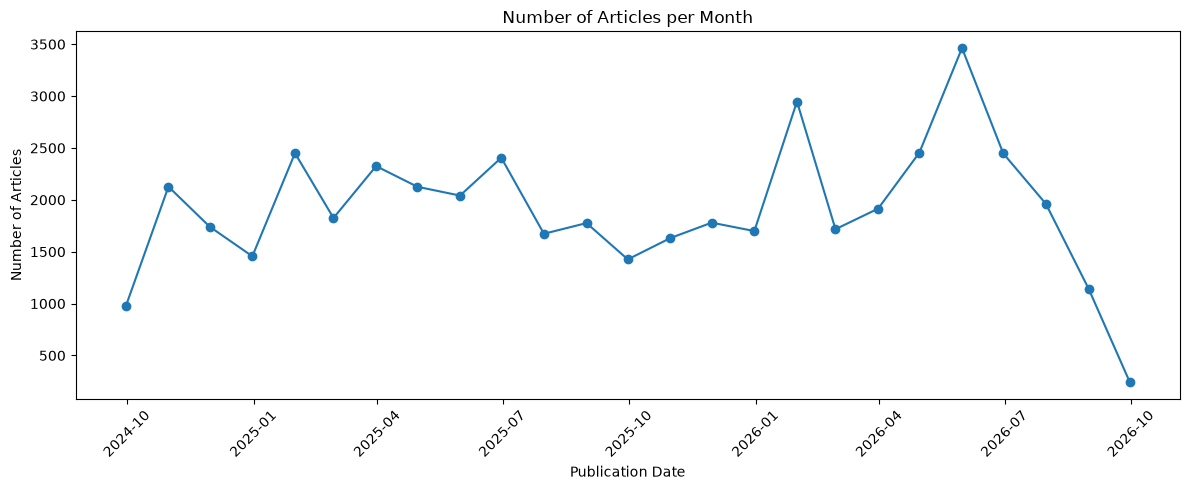

In [98]:
import matplotlib.pyplot as plt

articles_per_month = (
    df_clean
    .set_index("date")
    .resample("ME")
    .size()
    .reset_index(name="Articles")
)

plt.figure(figsize=(12, 5))

plt.plot(
    articles_per_month["date"],
    articles_per_month["Articles"],
    marker="o"
)

plt.title("Number of Articles per Month")
plt.xlabel("Publication Date")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Source Distribution

The dataset contains articles from a broad range of sources. The most frequently represented domains are examined to assess whether the dataset is dominated by a small number of publishers or provides relatively diverse source coverage.

In [99]:
top_sources = (
    df_clean["domain"]
    .value_counts()
    .head(15)
    .reset_index()
)

top_sources.columns = ["Source", "Articles"]

display(
    top_sources.style
    .hide(axis="index")
    .set_properties(subset=["Source"], **{"text-align": "left"})
    .set_properties(subset=["Articles"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Source,Articles
builtin,1669
aijourn,1627
apnews,1259
thenewstack,1176
dev,1138
marketbeat,1096
skyquestt,966
cnbc,833
crn,803
theconversation,802


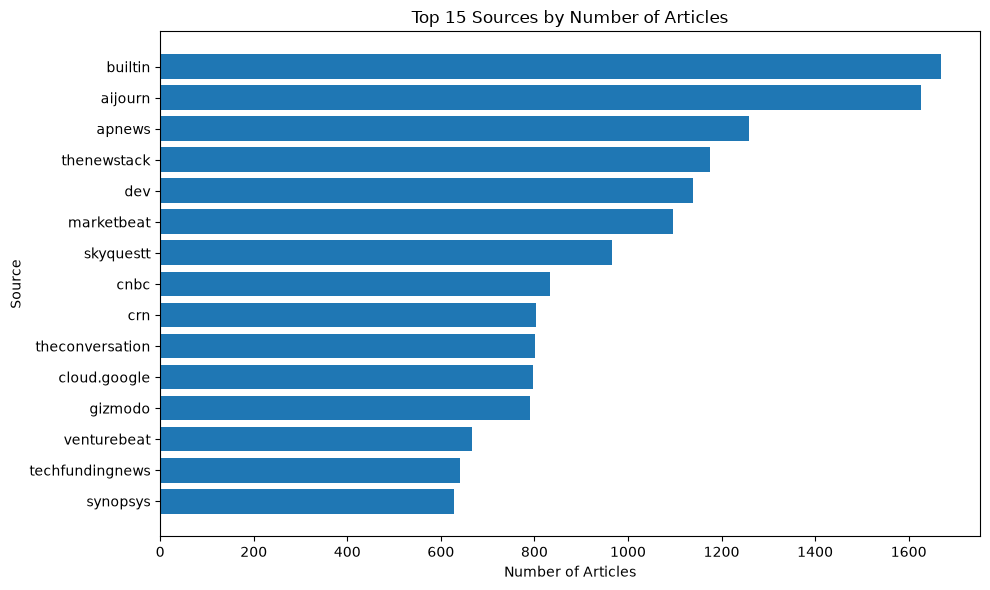

In [100]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_sources["Source"][::-1],
    top_sources["Articles"][::-1]
)

plt.title("Top 15 Sources by Number of Articles")
plt.xlabel("Number of Articles")
plt.ylabel("Source")

plt.tight_layout()
plt.show()

#### EDA Findings: Temporal and Source Coverage

The dataset shows substantial variation in monthly article volume across the observation period. Publication activity generally remains above 1,400 articles per month, with particularly high volumes in early and mid-2026.

The comparatively low values at the beginning and end of the time series should be interpreted cautiously because September 2024 and September 2026 represent only partial months in the dataset.

Source coverage is relatively diverse, with 392 unique domains. The largest contributors are `builtin` and `aijourn`, followed by sources such as `apnews`, `thenewstack`, and `dev`. The 15 most frequent sources account for approximately 31% of all records, indicating that although several publishers contribute substantially, the dataset is not dominated by only a small number of sources.

### Tag Distribution

The dataset contains 1,311 unique tags, with an average of approximately 5.23 tags per article. Tag frequencies are examined to identify the most prominent topics represented in the dataset and to provide an initial view of the thematic structure before focusing specifically on AI Governance.

In [101]:
from collections import Counter

tag_counts = Counter(
    tag
    for tags in df_clean["tags"]
    for tag in tags
)

top_tags = pd.DataFrame(
    tag_counts.most_common(20),
    columns=["Tag", "Articles"]
)

display(
    top_tags.style
    .hide(axis="index")
    .set_properties(subset=["Tag"], **{"text-align": "left"})
    .set_properties(subset=["Articles"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Tag,Articles
Video,9385
GenerativeAI,8614
Planning,8548
MilitaryAndDefense,7466
Personalisation,7099
OpenAI,6980
Accountability,6697
ConversationalAI,6297
LargeLanguageModel,6278
Robotics,6183


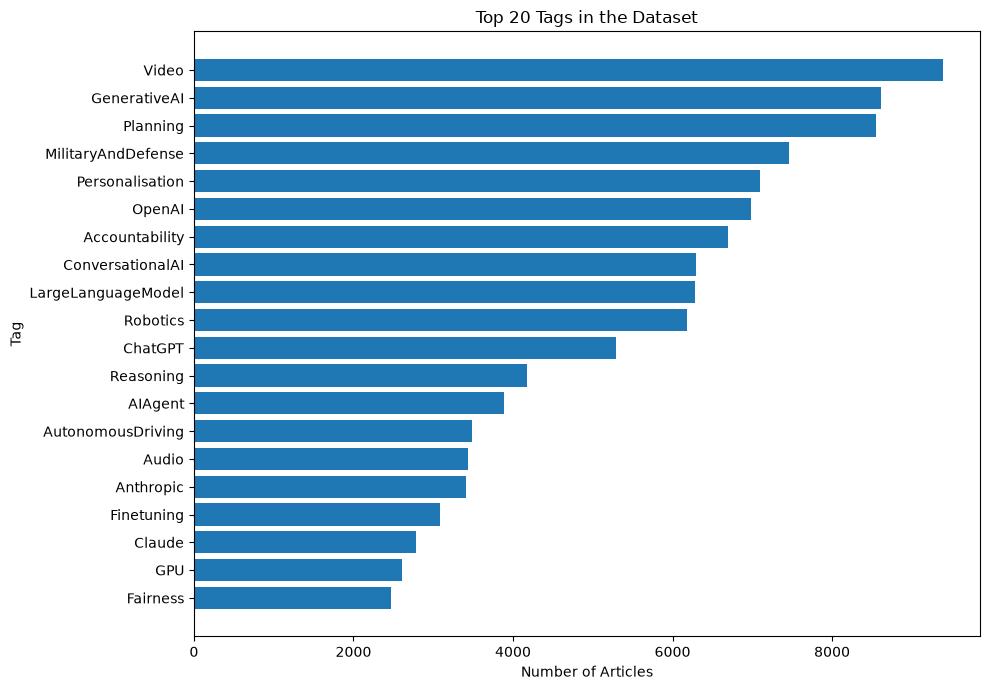

In [102]:
plt.figure(figsize=(10, 7))

plt.barh(
    top_tags["Tag"][::-1],
    top_tags["Articles"][::-1]
)

plt.title("Top 20 Tags in the Dataset")
plt.xlabel("Number of Articles")
plt.ylabel("Tag")

plt.tight_layout()
plt.show()

#### EDA Findings: Tag Distribution

The tag distribution shows that the dataset covers a broad range of technical, organizational, and societal AI topics. Frequently occurring tags include `GenerativeAI`, `Planning`, `OpenAI`, `LargeLanguageModel`, and `Robotics`.

Importantly for the AI Governance focus, `Accountability` is among the most frequent tags with 6,697 associated articles, while `Fairness` appears in 2,468 articles and is also among the 20 most frequent tags.

However, the absence of other governance themes from the top 20 does not imply that they are poorly represented. Related concepts may occur under more specific tags. Therefore, the complete tag vocabulary is examined for terms related to the four governance dimensions: Security, Accountability, Bias/Fairness, and Regulation.

### AI Governance Tag Exploration

To identify the terminology used for AI Governance within the dataset, the complete tag vocabulary is searched for tags that are potentially related to the four selected governance dimensions.

At this stage, the matching tags are treated as candidates rather than automatically classified as governance-relevant. This allows the available terminology to be inspected before defining the final thematic mapping.

In [103]:
governance_keywords = {
    "Security": [
        "security",
        "cyber",
        "privacy"
    ],
    "Accountability": [
        "accountab",
        "responsib",
        "transparen",
        "explainab"
    ],
    "Bias / Fairness": [
        "fair",
        "bias",
        "discrimin"
    ],
    "Regulation": [
        "regulat",
        "legislat",
        "compliance",
        "policy",
        "law"
    ]
}

governance_candidates = []

for tag, count in tag_counts.items():

    tag_lower = tag.lower()

    for theme, keywords in governance_keywords.items():

        if any(keyword in tag_lower for keyword in keywords):
            governance_candidates.append({
                "Governance Theme": theme,
                "Tag": tag,
                "Articles": count
            })

candidate_tags = (
    pd.DataFrame(governance_candidates)
    .sort_values(
        ["Governance Theme", "Articles"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(
    candidate_tags.style
    .hide(axis="index")
    .set_properties(
        subset=["Governance Theme", "Tag"],
        **{"text-align": "left"}
    )
    .set_properties(
        subset=["Articles"],
        **{"text-align": "right"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Governance Theme,Tag,Articles
Accountability,Accountability,6697
Accountability,ExplainableAI,52
Accountability,ResponsibleAI,23
Bias / Fairness,Fairness,2468
Bias / Fairness,AlgorithmicBias,376
Bias / Fairness,WeightsAndBiases,48
Regulation,AIPolicy,571
Regulation,OpenClaw,304
Regulation,ProximalPolicyOptimization,14
Regulation,Everlaw,2


#### EDA Findings: Governance Tag Exploration

The keyword-based search identified several potentially relevant governance tags, but also produced false-positive matches because some keywords occur within company names, product names, or technical terminology.

For example, `ProximalPolicyOptimization` refers to a reinforcement-learning method rather than regulatory policy, while `WeightsAndBiases` does not represent algorithmic bias in the governance sense.

Therefore, governance themes are defined using a curated set of semantically relevant tags rather than relying solely on substring matching.

In [104]:
governance_tag_mapping = {
    "Security": [
        "InternationalSecurity"
    ],
    "Accountability": [
        "Accountability",
        "ExplainableAI",
        "ResponsibleAI"
    ],
    "Bias / Fairness": [
        "Fairness",
        "AlgorithmicBias"
    ],
    "Regulation": [
        "AIPolicy"
    ]
}

In [105]:
broader_governance_keywords = [
    "govern",
    "ethic",
    "safety",
    "risk",
    "trust",
    "audit",
    "privacy",
    "data protection",
    "gdpr",
    "regulat",
    "policy",
    "law",
    "compliance",
    "transparen",
    "explain",
    "accountab",
    "responsib",
    "fair",
    "bias",
    "discrimin",
    "security",
    "cyber",
    "surveillance"
]

broader_candidates = []

for tag, count in tag_counts.items():

    tag_lower = tag.lower()

    if any(keyword in tag_lower for keyword in broader_governance_keywords):
        broader_candidates.append({
            "Tag": tag,
            "Articles": count
        })

broader_candidates = (
    pd.DataFrame(broader_candidates)
    .sort_values("Articles", ascending=False)
    .reset_index(drop=True)
)

display(
    broader_candidates.style
    .hide(axis="index")
    .set_properties(subset=["Tag"], **{"text-align": "left"})
    .set_properties(subset=["Articles"], **{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Tag,Articles
Accountability,6697
Fairness,2468
Surveillance,1783
AISafety,634
AIPolicy,571
AlgorithmicBias,376
OpenClaw,304
EthicalAI,248
InternationalSecurity,114
ExplainableAI,52


#### Broader Governance Tag Discovery

The initial keyword search revealed that simple substring matching can produce false-positive governance tags. To obtain a more complete picture of the available terminology, the full tag vocabulary is searched using a broader set of governance-related concepts.

The resulting tags are reviewed before being assigned to the final governance dimensions.

In [106]:
broader_governance_keywords = [
    "govern",
    "ethic",
    "safety",
    "risk",
    "trust",
    "audit",
    "privacy",
    "protection",
    "gdpr",
    "regulat",
    "legislat",
    "compliance",
    "policy",
    "law",
    "transparen",
    "explain",
    "accountab",
    "responsib",
    "fair",
    "bias",
    "discrimin",
    "security",
    "cyber",
    "surveillance"
]

broader_candidates = []

for tag, count in tag_counts.items():

    tag_lower = tag.lower()

    matched_keywords = [
        keyword
        for keyword in broader_governance_keywords
        if keyword in tag_lower
    ]

    if matched_keywords:
        broader_candidates.append({
            "Tag": tag,
            "Articles": count,
            "Matched Keyword": ", ".join(matched_keywords)
        })


broader_candidates = (
    pd.DataFrame(broader_candidates)
    .sort_values("Articles", ascending=False)
    .reset_index(drop=True)
)

display(
    broader_candidates.style
    .hide(axis="index")
    .set_properties(
        subset=["Tag", "Matched Keyword"],
        **{"text-align": "left"}
    )
    .set_properties(
        subset=["Articles"],
        **{"text-align": "right"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Tag,Articles,Matched Keyword
Accountability,6697,accountab
Fairness,2468,fair
Surveillance,1783,surveillance
AISafety,634,safety
AIPolicy,571,policy
AlgorithmicBias,376,bias
OpenClaw,304,law
EthicalAI,248,ethic
InternationalSecurity,114,security
ExplainableAI,52,explain


#### Final Governance Theme Definition

Based on the broader tag inspection, the candidate tags are manually reviewed to distinguish genuine AI Governance concepts from false-positive keyword matches.

Company names, product names, and unrelated technical concepts are excluded. The remaining tags are grouped into the four governance dimensions used throughout the project: Security, Accountability, Bias/Fairness, and Regulation.

The mapping is deliberately conservative to avoid classifying articles as governance-related based only on ambiguous terminology.

In [107]:
governance_tag_mapping = {
    "Security": [
        "AISafety",
        "InternationalSecurity",
        "Surveillance"
    ],
    
    "Accountability": [
        "Accountability",
        "ExplainableAI",
        "ResponsibleAI",
        "EthicalAI",
        "TrustworthyAI"
    ],
    
    "Bias / Fairness": [
        "Fairness",
        "AlgorithmicBias"
    ],
    
    "Regulation": [
        "AIPolicy"
    ]
}

In [108]:
def article_has_theme(tags, theme_tags):
    return any(tag in theme_tags for tag in tags)


for theme, theme_tags in governance_tag_mapping.items():

    column_name = (
        theme.lower()
        .replace(" / ", "_")
        .replace(" ", "_")
    )

    df_clean[column_name] = df_clean["tags"].apply(
        lambda tags: article_has_theme(tags, theme_tags)
    )


In [109]:
governance_theme_counts = pd.DataFrame({
    "Governance Theme": [
        "Security",
        "Accountability",
        "Bias / Fairness",
        "Regulation"
    ],
    "Articles": [
        int(df_clean["security"].sum()),
        int(df_clean["accountability"].sum()),
        int(df_clean["bias_fairness"].sum()),
        int(df_clean["regulation"].sum())
    ]
})

governance_theme_counts["Share of Dataset (%)"] = (
    governance_theme_counts["Articles"]
    / len(df_clean)
    * 100
).round(2)

display(
    governance_theme_counts.style
    .hide(axis="index")
    .set_properties(
        subset=["Governance Theme"],
        **{"text-align": "left"}
    )
    .set_properties(
        subset=["Articles", "Share of Dataset (%)"],
        **{"text-align": "right"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)


Governance Theme,Articles,Share of Dataset (%)
Security,2432,5.090000
Accountability,6890,14.430000
Bias / Fairness,2673,5.600000
Regulation,571,1.200000


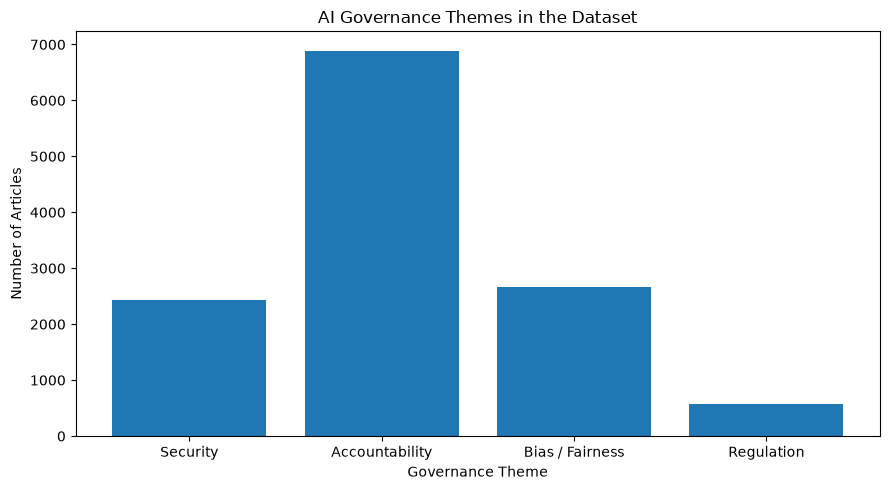

In [110]:
plt.figure(figsize=(9, 5))

plt.bar(
    governance_theme_counts["Governance Theme"],
    governance_theme_counts["Articles"]
)

plt.title("AI Governance Themes in the Dataset")
plt.xlabel("Governance Theme")
plt.ylabel("Number of Articles")

plt.tight_layout()
plt.show()

#### EDA Findings: Governance Theme Coverage

Among the four selected AI Governance dimensions, Accountability is the most frequently represented theme, appearing in 6,890 articles (14.43% of the dataset).

Bias/Fairness and Security are represented in 2,673 (5.60%) and 2,432 (5.09%) articles respectively, while Regulation is less frequent with 571 articles (1.20%).

Since individual articles may be associated with more than one governance theme, these percentages are not mutually exclusive and should not be summed to estimate the overall share of governance-related content.

#### Overall AI Governance Coverage

To estimate the overall relevance of AI Governance within the dataset, articles associated with at least one of the four governance dimensions are compared with all remaining articles.

In [111]:
governance_columns = [
    "security",
    "accountability",
    "bias_fairness",
    "regulation"
]

df_clean["governance_related"] = (
    df_clean[governance_columns]
    .any(axis=1)
)

governance_articles = int(
    df_clean["governance_related"].sum()
)

other_articles = (
    len(df_clean) - governance_articles
)

governance_coverage = pd.DataFrame({
    "Category": [
        "Governance-related",
        "Other articles"
    ],
    "Articles": [
        governance_articles,
        other_articles
    ]
})

governance_coverage

,Category,Articles
0,Governance-related,10796
1,Other articles,36955


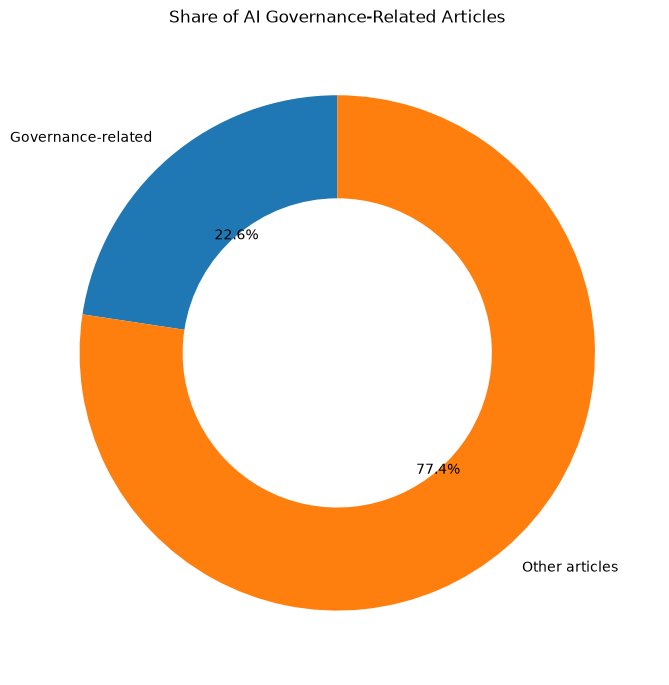

In [112]:
plt.figure(figsize=(7, 7))

plt.pie(
    governance_coverage["Articles"],
    labels=governance_coverage["Category"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Share of AI Governance-Related Articles")

plt.tight_layout()
plt.show()

### Governance Theme Overlap

Because AI Governance dimensions are not mutually exclusive, their co-occurrence is examined at article level. This helps identify relationships between governance themes and provides an initial basis for the later knowledge graph.

In [113]:
theme_labels = {
    "security": "Security",
    "accountability": "Accountability",
    "bias_fairness": "Bias / Fairness",
    "regulation": "Regulation"
}

overlap_matrix = pd.DataFrame(
    index=theme_labels.values(),
    columns=theme_labels.values(),
    dtype=int
)

for col_a, label_a in theme_labels.items():
    for col_b, label_b in theme_labels.items():

        overlap_matrix.loc[label_a, label_b] = int(
            (
                df_clean[col_a]
                & df_clean[col_b]
            ).sum()
        )

display(overlap_matrix)

,Security,Accountability,Bias / Fairness,Regulation
Security,2432.0,531.0,290.0,110.0
Accountability,531.0,6890.0,857.0,131.0
Bias / Fairness,290.0,857.0,2673.0,84.0
Regulation,110.0,131.0,84.0,571.0


#### Governance Theme Co-Occurrence

The overlap between governance dimensions is visualized to identify which themes are most frequently discussed together within the same articles.

The diagonal represents the total number of articles associated with each individual theme, while the off-diagonal values represent co-occurrences between two themes.

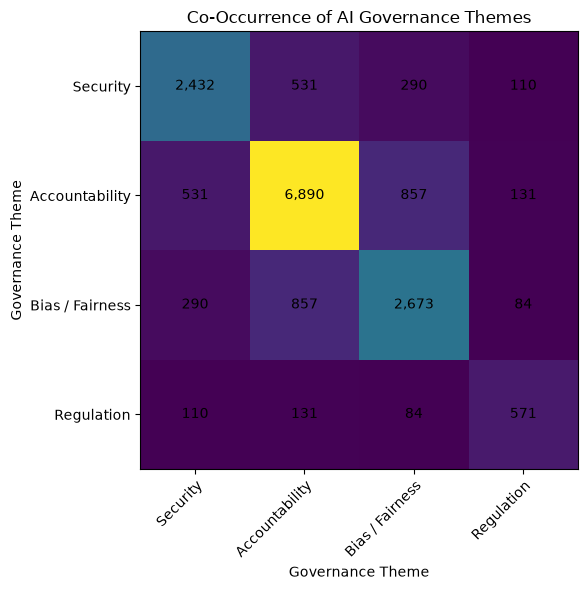

In [114]:
import numpy as np
import matplotlib.pyplot as plt

matrix_values = overlap_matrix.astype(int).values
labels = overlap_matrix.index.tolist()

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(matrix_values)

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))

ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)

# Add values to each cell
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(
            j,
            i,
            f"{matrix_values[i, j]:,}",
            ha="center",
            va="center"
        )

ax.set_title("Co-Occurrence of AI Governance Themes")
ax.set_xlabel("Governance Theme")
ax.set_ylabel("Governance Theme")

fig.tight_layout()
plt.show()

### Governance Theme Breadth

To examine whether governance-related articles focus on individual issues or combine several dimensions, the number of governance themes associated with each article is calculated.

Each governance-related article can therefore cover between one and four of the selected dimensions.

In [115]:
display(
    theme_breadth.style
    .hide(axis="index")
    .format({
        "Number of Governance Themes": "{:.0f}",
        "Articles": "{:.0f}",
        "Share (%)": "{:.2f}"
    })
    .set_properties(
        subset=[
            "Number of Governance Themes",
            "Articles",
            "Share (%)"
        ],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

NameError: name 'theme_breadth' is not defined

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))

wedges, _ = ax.pie(
    theme_breadth["Articles"],
    startangle=90,
    wedgeprops={"width": 0.4}
)

legend_labels = [
    (
        f"{int(row['Number of Governance Themes'])} "
        f"{'theme' if row['Number of Governance Themes'] == 1 else 'themes'}"
        f" — {int(row['Articles']):,} articles "
        f"({row['Share (%)']:.2f}%)"
    )
    for _, row in theme_breadth.iterrows()
]

ax.legend(
    wedges,
    legend_labels,
    title="Governance Theme Coverage",
    loc="center left",
    bbox_to_anchor=(-0.62, 0.5),
    frameon=False
)

ax.set_title(
    "Number of Governance Themes per Governance-Related Article",
    pad=20
)

plt.subplots_adjust(left=0.30, right=0.95)

plt.show()

#### EDA Findings: Governance Theme Breadth

Most governance-related articles focus on a single governance dimension. Of the 10,796 governance-related articles, 9,245 (85.63%) are associated with only one of the four selected themes.

A further 1,346 articles (12.47%) cover two governance dimensions, while articles spanning three or all four themes are comparatively rare.

This suggests that governance-related coverage in the dataset is predominantly theme-specific rather than broadly cross-cutting.

### Governance Themes Over Time

The monthly development of the four governance dimensions is examined to identify changes in their prevalence throughout the observation period.

Since an article may be associated with more than one governance theme, the monthly theme counts are not mutually exclusive.

In [ ]:
monthly_governance = (
    df_clean
    .set_index("date")[[
        "security",
        "accountability",
        "bias_fairness",
        "regulation"
    ]]
    .resample("ME")
    .sum()
    .reset_index()
)

monthly_governance = monthly_governance.rename(columns={
    "security": "Security",
    "accountability": "Accountability",
    "bias_fairness": "Bias / Fairness",
    "regulation": "Regulation"
})

monthly_governance.head()

In [ ]:
plt.figure(figsize=(12, 6))

for theme in [
    "Security",
    "Accountability",
    "Bias / Fairness",
    "Regulation"
]:
    plt.plot(
        monthly_governance["date"],
        monthly_governance[theme],
        marker="o",
        markersize=3,
        label=theme
    )

plt.title("Monthly Development of AI Governance Themes")
plt.xlabel("Month")
plt.ylabel("Number of Articles")

plt.legend(
    title="Governance Theme",
    frameon=False
)

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### EDA Findings: Governance Themes Over Time

Accountability is the most frequently represented governance dimension throughout most of the observation period. Its absolute article volume increases markedly during parts of 2026, reaching its highest levels in the middle of the year before declining again toward August.

Security and Bias/Fairness occur at lower and relatively similar levels, while Regulation remains the least frequently represented theme throughout the analyzed period.

However, these values represent absolute monthly article counts. Since the overall number of articles also varies considerably between months, absolute increases do not necessarily indicate that a governance theme became more prominent within the dataset. Relative monthly shares are therefore examined next.

### Relative Monthly Prevalence of Governance Themes

Absolute theme counts can be influenced by changes in the overall number of articles available in a given month.

To account for differences in monthly publication volume, the number of articles associated with each governance theme is therefore expressed as a percentage of all articles published during the respective month.

This allows changes in the relative prominence of each governance dimension to be compared over time.

In [ ]:
monthly_total_articles = (
    df_clean
    .set_index("date")
    .resample("ME")
    .size()
)

monthly_governance_share = (
    monthly_governance
    .set_index("date")[
        [
            "Security",
            "Accountability",
            "Bias / Fairness",
            "Regulation"
        ]
    ]
    .div(monthly_total_articles, axis=0)
    .mul(100)
    .reset_index()
)

monthly_governance_share.head()

In [ ]:
plt.figure(figsize=(12, 6))

for theme in [
    "Security",
    "Accountability",
    "Bias / Fairness",
    "Regulation"
]:
    plt.plot(
        monthly_governance_share["date"],
        monthly_governance_share[theme],
        marker="o",
        markersize=3,
        label=theme
    )

plt.title("Monthly Share of Articles by AI Governance Theme")
plt.xlabel("Month")
plt.ylabel("Share of Monthly Articles (%)")

plt.legend(
    title="Governance Theme",
    frameon=False
)

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### EDA Findings: Relative Governance Theme Prevalence

Normalizing the governance-theme counts by total monthly publication volume confirms that the increasing prominence of Accountability is not solely explained by changes in the number of articles collected each month.

Accountability becomes increasingly prevalent over the observation period, particularly during 2026. Security remains comparatively stable, while Bias/Fairness shows greater month-to-month variation. Regulation consistently represents the smallest share of monthly articles.

The first and last months of the observation period contain only partial monthly coverage and should therefore be interpreted with caution.

### Sources of AI Governance-Related Coverage

The distribution of governance-related articles across publishing domains is examined to identify which sources contribute most strongly to the AI Governance subset of the dataset.

In [ ]:
top_governance_sources = (
    df_clean.loc[df_clean["governance_related"], "domain"]
    .value_counts()
    .head(15)
    .reset_index()
)

top_governance_sources.columns = [
    "Source",
    "Governance Articles"
]

display(
    top_governance_sources.style
    .hide(axis="index")
    .set_properties(
        subset=["Source", "Governance Articles"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_governance_sources["Source"][::-1],
    top_governance_sources["Governance Articles"][::-1]
)

plt.title("Top Sources of AI Governance-Related Articles")
plt.xlabel("Number of Governance-Related Articles")
plt.ylabel("Source")

plt.tight_layout()
plt.show()

#### EDA Findings: Sources of Governance-Related Coverage

AI Governance-related coverage is distributed across a broad range of publishing domains. The largest contributors are builtin, aijourn and dev, while sources such as csis, kpmg, ey and foreignpolicy also appear among the most frequent contributors.

The 15 largest sources account for approximately 37% of all governance-related articles. This indicates that several publishers contribute substantially to the governance subset, while the majority of governance-related articles are still distributed across a wider range of sources.

### Focused Analysis: Accountability Over Time

The previous temporal analysis indicates a marked increase in the absolute number of Accountability-related articles during parts of 2026.

To distinguish between changes in overall publication volume and changes in the relative prominence of Accountability, monthly article volume, Accountability-related article counts and Accountability's share of monthly coverage are examined together.

In [116]:
accountability_monthly = (
    df_clean
    .set_index("date")
    .resample("ME")
    .agg(
        Total_Articles=("record_id", "count"),
        Accountability_Articles=("accountability", "sum")
    )
    .reset_index()
)

# Keep only complete months
accountability_monthly = accountability_monthly[
    (accountability_monthly["date"] >= "2024-10-31") &
    (accountability_monthly["date"] <= "2026-08-31")
].copy()

accountability_monthly["Accountability Share (%)"] = (
    accountability_monthly["Accountability_Articles"]
    / accountability_monthly["Total_Articles"]
    * 100
).round(2)

display(
    accountability_monthly.style
    .hide(axis="index")
    .format({
        "date": lambda x: x.strftime("%Y-%m"),
        "Total_Articles": "{:,.0f}",
        "Accountability_Articles": "{:,.0f}",
        "Accountability Share (%)": "{:.2f}"
    })
    .set_properties(
        subset=[
            "date",
            "Total_Articles",
            "Accountability_Articles",
            "Accountability Share (%)"
        ],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

date,Total_Articles,Accountability_Articles,Accountability Share (%)
2024-10,"2,127",204,9.59
2024-11,"1,741",160,9.19
2024-12,"1,456",169,11.61
2025-01,"2,450",293,11.96
2025-02,"1,825",227,12.44
2025-03,"2,325",275,11.83
2025-04,"2,126",241,11.34
2025-05,"2,041",261,12.79
2025-06,"2,406",254,10.56
2025-07,"1,673",231,13.81


#### Relationship Between Publication Volume and Accountability Coverage

To assess whether the increase in Accountability-related articles is associated with changes in overall publication volume, the relationship between total monthly article volume and Accountability-related article volume is examined.

In [117]:
accountability_correlation = accountability_monthly[
    [
        "Total_Articles",
        "Accountability_Articles"
    ]
].corr().iloc[0, 1]

print(
    f"Correlation between total monthly article volume "
    f"and Accountability article volume: "
    f"{accountability_correlation:.3f}"
)

Correlation between total monthly article volume and Accountability article volume: 0.751


#### Relative Development of Publication Volume and Accountability Coverage

To compare their development despite different absolute scales, total article volume and Accountability-related article volume are indexed to 100 in the first complete month of the analysis.

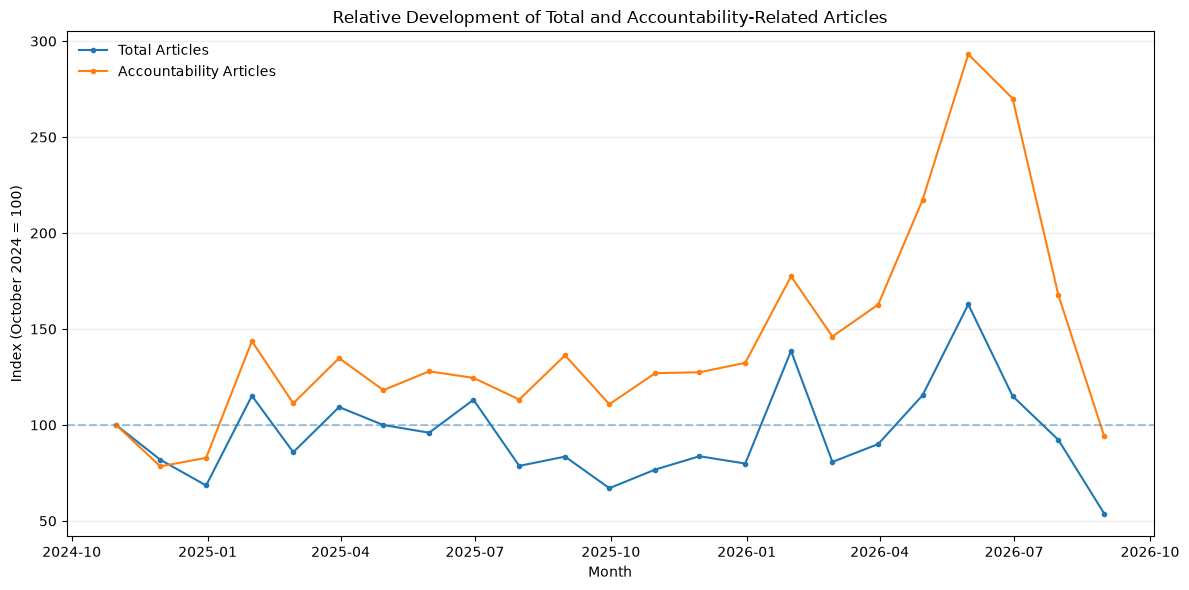

In [118]:
accountability_indexed = accountability_monthly[
    [
        "date",
        "Total_Articles",
        "Accountability_Articles"
    ]
].copy()

accountability_indexed["Total Articles Index"] = (
    accountability_indexed["Total_Articles"]
    / accountability_indexed["Total_Articles"].iloc[0]
    * 100
)

accountability_indexed["Accountability Index"] = (
    accountability_indexed["Accountability_Articles"]
    / accountability_indexed["Accountability_Articles"].iloc[0]
    * 100
)

plt.figure(figsize=(12, 6))

plt.plot(
    accountability_indexed["date"],
    accountability_indexed["Total Articles Index"],
    marker="o",
    markersize=3,
    label="Total Articles"
)

plt.plot(
    accountability_indexed["date"],
    accountability_indexed["Accountability Index"],
    marker="o",
    markersize=3,
    label="Accountability Articles"
)

plt.axhline(
    100,
    linestyle="--",
    alpha=0.4
)

plt.title("Relative Development of Total and Accountability-Related Articles")
plt.xlabel("Month")
plt.ylabel("Index (October 2024 = 100)")

plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Interpretation

The monthly volume of Accountability-related articles is positively associated with overall publication volume (r = 0.751), indicating that part of the increase can be explained by changes in the total number of articles published.

However, the indexed comparison and the monthly share show that overall publication volume does not fully explain the development. Accountability-related coverage grows substantially faster than total article volume during several periods, particularly in 2026.

The share of Accountability-related articles increases from around 9–12% in late 2024 to approximately 14–16% during much of the second half of 2025. In 2026, the share remains generally higher and reaches a maximum of 22.52% in June 2026.

Overall, this suggests that Accountability became increasingly prominent within the analysed AI media coverage, rather than the rise in Accountability-related articles being caused solely by higher overall publication volume.

## Topic-Focused Knowledge Graph
The previous analysis examined how the four AI Governance themes — Security, Accountability, Bias/Fairness and Regulation — are represented across the dataset.

The next step moves from frequency-based analysis to the relationships between entities appearing in governance-related articles. A topic-focused Knowledge Graph is constructed to represent relevant entities and their connections within the AI Governance context.

The process consists of selecting the relevant governance articles, extracting entities, identifying meaningful relationships and representing these relationships as a graph.

### Knowledge Graph Preparation

First, the governance-related subset is prepared for entity and relation extraction. Only the textual information required for the Knowledge Graph is retained.

In [121]:
# Select articles associated with at least one AI Governance theme
governance_df = df_clean.loc[
    df_clean["governance_related"],
    [
        "record_id",
        "title",
        "date",
        "domain",
        "url",
        "tags",
        "content_text",
        "security",
        "accountability",
        "bias_fairness",
        "regulation"
    ]
].copy()

# Reset the index so the governance subset has a clean sequential index
governance_df = governance_df.reset_index(drop=True)

print(f"Governance-related articles: {len(governance_df):,}")
print(f"Columns retained: {governance_df.shape[1]}")

Governance-related articles: 10,796
Columns retained: 11


The Knowledge Graph is built from the governance-related subset rather than the full dataset. This reduces unrelated content while preserving the article text, metadata and governance-theme classifications required for entity and relation extraction.

### Entity Extraction

The Knowledge Graph requires identifiable entities that can act as nodes. Named Entity Recognition (NER) is therefore applied to the governance-related article text.

The extraction focuses on organisations, persons, geopolitical entities and products, as these entity types are particularly relevant for analysing relationships within AI Governance discussions.

In [125]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy model loaded successfully.")

spaCy model loaded successfully.


In [128]:
import time
import pandas as pd

benchmark_results = []

# Test full-text entity extraction on the first 10 governance articles
for i, row in governance_df.head(10).iterrows():

    title = row["title"] if pd.notna(row["title"]) else ""
    content = row["content_text"] if pd.notna(row["content_text"]) else ""

    # Use the complete article text
    full_text = f"{title}. {content}"

    start_time = time.perf_counter()

    doc = nlp(
        full_text,
        disable=["parser", "tagger", "lemmatizer", "attribute_ruler"]
    )

    elapsed = time.perf_counter() - start_time

    # Count relevant entities for additional context
    relevant_entities = [
        ent for ent in doc.ents
        if ent.label_ in ENTITY_TYPES
    ]

    benchmark_results.append({
        "Article": len(benchmark_results) + 1,
        "Content Characters": len(content),
        "Total Characters": len(full_text),
        "Processing Time (sec)": round(elapsed, 2),
        "Relevant Entities": len(relevant_entities)
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df)

print(
    f"\nAverage article length: "
    f"{benchmark_df['Content Characters'].mean():,.0f} characters"
)

print(
    f"Average processing time: "
    f"{benchmark_df['Processing Time (sec)'].mean():.2f} seconds/article"
)

estimated_minutes = (
    benchmark_df["Processing Time (sec)"].mean()
    * len(governance_df)
    / 60
)

print(
    f"Rough estimated time for all {len(governance_df):,} articles: "
    f"{estimated_minutes:.1f} minutes"
)

,Article,Content Characters,Total Characters,Processing Time (sec),Relevant Entities
0,1,16699,16738,0.62,81
1,2,5068,5185,0.17,6
2,3,8395,8433,0.29,33
3,4,35810,35864,1.15,149
4,5,7152,7198,0.24,25
5,6,5252,5331,0.19,19
6,7,6789,6861,0.23,45
7,8,29263,29382,1.06,171
8,9,17301,17427,0.62,164
9,10,15436,15484,0.59,27



Average article length: 14,716 characters
Average processing time: 0.52 seconds/article
Rough estimated time for all 10,796 articles: 92.8 minutes


In [130]:
import gc
import pickle
import time

# Remove large temporary objects from earlier extraction attempts
# so they do not unnecessarily remain in memory.
for variable_name in ["governance_texts", "entity_lists"]:
    globals().pop(variable_name, None)

gc.collect()


# Entity types retained for the AI Governance Knowledge Graph
ENTITY_TYPES = {
    "ORG",      # Organisations and companies
    "PERSON",   # Individuals
    "GPE",      # Countries, cities and geopolitical entities
    "LAW",      # Laws and regulations
    "PRODUCT"   # Technologies and products
}


# Paths for resumable extraction
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = (
    PROCESSED_DIR /
    "governance_entities_fulltext_checkpoint.pkl"
)

FINAL_PATH = (
    PROCESSED_DIR /
    "governance_entities_fulltext.pkl"
)


def save_checkpoint(entity_results):
    """
    Save the already completed entity extractions.

    A temporary file is written first and then renamed to reduce
    the risk of creating a corrupted checkpoint.
    """

    checkpoint_data = {
        "mode": "full_text",
        "spacy_model": nlp.meta.get("name"),
        "spacy_model_version": nlp.meta.get("version"),
        "entity_types": sorted(ENTITY_TYPES),
        "results": entity_results
    }

    temp_path = CHECKPOINT_PATH.with_suffix(".tmp")

    with open(temp_path, "wb") as file:
        pickle.dump(
            checkpoint_data,
            file,
            protocol=pickle.HIGHEST_PROTOCOL
        )

    temp_path.replace(CHECKPOINT_PATH)


# ---------------------------------------------------------
# If the complete result already exists, simply load it.
# ---------------------------------------------------------

if FINAL_PATH.exists():

    governance_df = pd.read_pickle(FINAL_PATH)

    print("Full entity extraction already completed.")
    print(
        f"Loaded {len(governance_df):,} processed articles "
        f"from {FINAL_PATH.name}"
    )


# ---------------------------------------------------------
# Otherwise continue from the last available checkpoint.
# ---------------------------------------------------------

else:

    if CHECKPOINT_PATH.exists():

        with open(CHECKPOINT_PATH, "rb") as file:
            checkpoint_data = pickle.load(file)

        # Ensure that the checkpoint belongs to this extraction setup
        if checkpoint_data.get("mode") != "full_text":
            raise ValueError(
                "The existing checkpoint was not created "
                "with full-text extraction."
            )

        if checkpoint_data.get("entity_types") != sorted(ENTITY_TYPES):
            raise ValueError(
                "The entity types differ from the existing checkpoint."
            )

        entity_results = checkpoint_data["results"]

        print(
            f"Checkpoint found: "
            f"{len(entity_results):,} articles already processed."
        )

    else:

        entity_results = {}

        print("No checkpoint found. Starting full-text extraction.")


    # Ensure that the checkpoint corresponds to the current dataset
    valid_record_ids = set(governance_df["record_id"])

    unknown_ids = (
        set(entity_results.keys()) - valid_record_ids
    )

    if unknown_ids:
        raise ValueError(
            "The checkpoint contains record IDs that are not "
            "present in the current governance dataset."
        )


    total_articles = len(governance_df)

    completed_ids = set(entity_results.keys())

    pending_df = governance_df.loc[
        ~governance_df["record_id"].isin(completed_ids),
        ["record_id", "title", "content_text"]
    ].copy()

    print(f"Total governance articles: {total_articles:,}")
    print(f"Already completed: {len(entity_results):,}")
    print(f"Remaining: {len(pending_df):,}")


    # Prevent spaCy's document-length limit from causing an error
    if len(pending_df) > 0:

        max_text_length = (
            pending_df["title"].fillna("").str.len()
            + pending_df["content_text"].fillna("").str.len()
            + 2
        ).max()

        if max_text_length > nlp.max_length:
            nlp.max_length = int(max_text_length + 1000)


    def pending_text_generator():
        """
        Generate one complete article at a time.

        Using a generator avoids keeping an additional copy of
        all article texts in memory.
        """

        for row in pending_df.itertuples(index=False):

            title = (
                row.title
                if isinstance(row.title, str)
                else ""
            )

            content = (
                row.content_text
                if isinstance(row.content_text, str)
                else ""
            )

            full_text = f"{title}. {content}"

            # record_id is passed through spaCy together with the text
            yield full_text, row.record_id


    start_time = time.perf_counter()
    session_processed = 0
    interrupted = False


    try:

        for doc, record_id in nlp.pipe(
            pending_text_generator(),
            as_tuples=True,
            batch_size=4,
            disable=[
                "parser",
                "tagger",
                "lemmatizer",
                "attribute_ruler"
            ]
        ):

            article_entities = []
            seen_entities = set()

            for ent in doc.ents:

                entity_text = (
                    " ".join(ent.text.split()).strip()
                )

                # Keep relevant entity types and avoid duplicates
                # within the same article.
                if (
                    ent.label_ in ENTITY_TYPES
                    and len(entity_text) > 1
                ):

                    entity = (
                        entity_text,
                        ent.label_
                    )

                    if entity not in seen_entities:

                        article_entities.append(entity)
                        seen_entities.add(entity)


            # Store result using the permanent record identifier
            entity_results[record_id] = article_entities

            session_processed += 1

            total_completed = len(entity_results)


            # Save a checkpoint every 250 newly processed articles.
            # In addition, an interrupt is caught and saved below.
            if session_processed % 250 == 0:
                save_checkpoint(entity_results)


            # Print progress every 1,000 completed articles
            if (
                total_completed % 1000 == 0
                or total_completed == total_articles
            ):

                elapsed = (
                    time.perf_counter() - start_time
                )

                processing_rate = (
                    session_processed / elapsed
                )

                remaining_articles = (
                    total_articles - total_completed
                )

                estimated_remaining = (
                    remaining_articles / processing_rate
                    if processing_rate > 0
                    else 0
                )

                print(
                    f"{total_completed:,} / "
                    f"{total_articles:,} articles "
                    f"({total_completed / total_articles:.1%}) | "
                    f"Session time: {elapsed / 60:.1f} min | "
                    f"Estimated remaining: "
                    f"{estimated_remaining / 60:.1f} min"
                )


    except KeyboardInterrupt:

        # Preserve everything completed before the interruption
        save_checkpoint(entity_results)

        interrupted = True

        print("\nExtraction interrupted safely.")
        print(
            f"Saved progress: "
            f"{len(entity_results):,} / "
            f"{total_articles:,} articles."
        )
        print(
            "Run this cell again to continue "
            "from the saved checkpoint."
        )


# ---------------------------------------------------------
# Save the final complete dataset
# ---------------------------------------------------------

if not interrupted:

    save_checkpoint(entity_results)

    governance_df["entities"] = (
        governance_df["record_id"]
        .map(entity_results)
    )

    missing_entity_results = (
        governance_df["entities"].isna().sum()
    )

    if missing_entity_results != 0:
        raise ValueError(
            f"{missing_entity_results} articles are "
            "missing entity extraction results."
        )

    governance_df.to_pickle(FINAL_PATH)

    articles_with_entities = (
        governance_df["entities"]
        .apply(len)
        .gt(0)
        .sum()
    )

    print("\nEntity extraction complete.")
    print(
        f"Articles processed: "
        f"{len(governance_df):,}"
    )
    print(
        f"Articles with at least one entity: "
        f"{articles_with_entities:,}"
    )
    print(
        f"Final dataset saved to: "
        f"{FINAL_PATH}"
    )

No checkpoint found. Starting full-text extraction.
Total governance articles: 10,796
Already completed: 0
Remaining: 10,796
1,000 / 10,796 articles (9.3%) | Session time: 7.6 min | Estimated remaining: 74.7 min
2,000 / 10,796 articles (18.5%) | Session time: 14.8 min | Estimated remaining: 65.1 min
3,000 / 10,796 articles (27.8%) | Session time: 21.9 min | Estimated remaining: 57.0 min
4,000 / 10,796 articles (37.1%) | Session time: 28.5 min | Estimated remaining: 48.5 min
5,000 / 10,796 articles (46.3%) | Session time: 35.3 min | Estimated remaining: 41.0 min
6,000 / 10,796 articles (55.6%) | Session time: 48.4 min | Estimated remaining: 38.7 min
7,000 / 10,796 articles (64.8%) | Session time: 55.2 min | Estimated remaining: 30.0 min
8,000 / 10,796 articles (74.1%) | Session time: 63.4 min | Estimated remaining: 22.2 min
9,000 / 10,796 articles (83.4%) | Session time: 71.0 min | Estimated remaining: 14.2 min
10,000 / 10,796 articles (92.6%) | Session time: 78.2 min | Estimated remain

#### Entity Extraction Quality Check

Before constructing relationships and the Knowledge Graph, the extracted entities are inspected for frequency, entity-type distribution and potential inconsistencies.

Because entities were deduplicated within each article during extraction, the frequency reported below represents the number of governance-related articles in which an entity appears, rather than its total number of textual mentions.

This inspection helps identify common entities, possible naming variants and noisy or incorrectly classified entities that may require normalization before relation extraction.

In [131]:
from collections import Counter

# Count in how many articles each entity-label combination occurs.
# Entities were already deduplicated within individual articles,
# so these counts represent article frequency.
entity_counter = Counter(
    entity
    for entities in governance_df["entities"]
    for entity in entities
)

entity_frequency = pd.DataFrame(
    [
        {
            "Entity": entity_text,
            "Type": entity_type,
            "Article Frequency": count
        }
        for (entity_text, entity_type), count
        in entity_counter.items()
    ]
)

entity_frequency = (
    entity_frequency
    .sort_values(
        "Article Frequency",
        ascending=False
    )
    .reset_index(drop=True)
)


# Summary of extracted entity types
entity_type_summary = (
    entity_frequency
    .groupby("Type")
    .agg(
        Unique_Entities=("Entity", "nunique"),
        Total_Article_Occurrences=("Article Frequency", "sum")
    )
    .sort_values(
        "Total_Article_Occurrences",
        ascending=False
    )
    .reset_index()
)


print(
    f"Unique entity-label combinations: "
    f"{len(entity_frequency):,}"
)

print(
    f"Unique entity names: "
    f"{entity_frequency['Entity'].nunique():,}"
)

print("\nEntity types:")
display(entity_type_summary)

print("\nMost frequent extracted entities:")
display(entity_frequency.head(50))

Unique entity-label combinations: 156,612
Unique entity names: 148,655

Entity types:


,Type,Unique_Entities,Total_Article_Occurrences
0,ORG,87108,221085
1,PERSON,54139,103326
2,GPE,9635,68901
3,PRODUCT,4025,9351
4,LAW,1705,3249



Most frequent extracted entities:


,Entity,Type,Article Frequency
0,AI,GPE,8505
1,AI,ORG,6798
2,U.S.,GPE,2090
3,US,GPE,1863
4,Google,ORG,1737
5,the United States,GPE,1593
6,China,GPE,1370
7,API,ORG,1326
8,Microsoft,ORG,1258
9,UK,GPE,1163


#### Entity Label Consistency

The initial quality check shows that some frequently occurring entities are assigned to multiple entity types by the pretrained NER model.

Before constructing relationships, entities with inconsistent labels are identified. This allows high-frequency ambiguities and systematic classification errors to be reviewed and normalized before they propagate into the Knowledge Graph.

In [132]:
# Identify entity names that spaCy assigned to more than one entity type

entity_label_variants = (
    entity_frequency
    .groupby("Entity")
    .agg(
        Number_of_Types=("Type", "nunique"),
        Types=("Type", lambda x: ", ".join(sorted(set(x)))),
        Total_Article_Frequency=("Article Frequency", "sum")
    )
    .reset_index()
)

# Keep only entities with conflicting classifications
ambiguous_entities = (
    entity_label_variants
    .loc[entity_label_variants["Number_of_Types"] > 1]
    .sort_values(
        "Total_Article_Frequency",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"Entities assigned to multiple types: "
    f"{len(ambiguous_entities):,}"
)

display(
    ambiguous_entities.head(50)
)

Entities assigned to multiple types: 7,021


,Entity,Number_of_Types,Types,Total_Article_Frequency
0,AI,4,"GPE, ORG, PERSON, PRODUCT",15344
1,OpenAI,3,"GPE, ORG, PERSON",2234
2,US,2,"GPE, ORG",1864
3,Google,4,"GPE, ORG, PERSON, PRODUCT",1751
4,Trump,2,"ORG, PERSON",1686
5,the United States,2,"GPE, ORG",1598
6,API,2,"ORG, PERSON",1330
7,Microsoft,2,"GPE, ORG",1259
8,LLM,2,"ORG, PRODUCT",1040
9,EU,2,"GPE, ORG",889


#### Entity Normalization

The quality check revealed systematic inconsistencies in the labels assigned by the pretrained NER model. In particular, several frequently occurring AI-specific terms, organisations and technologies were assigned to multiple entity types.

A conservative rule-based normalization layer is therefore applied before relation extraction. Only high-confidence aliases and classifications are corrected, while ambiguous entities are retained for further inspection.

The original extracted entities remain unchanged in order to preserve traceability. Normalized entities are stored separately and used for subsequent Knowledge Graph construction.

In [133]:
# High-confidence aliases used to merge common naming variants
ENTITY_ALIASES = {
    "AI": "Artificial Intelligence",
    "GenAI": "Generative AI",
    "ML": "Machine Learning",
    "LLM": "Large Language Model",
    "RAG": "Retrieval-Augmented Generation",
    "MCP": "Model Context Protocol",
    "IoT": "Internet of Things",

    "U.S.": "United States",
    "US": "United States",
    "the United States": "United States",
    "UK": "United Kingdom"
}


# High-confidence type corrections for frequently occurring entities.
# Custom types such as TECHNOLOGY, MODEL and STANDARD make the
# resulting Knowledge Graph more meaningful than the raw spaCy labels.
ENTITY_TYPE_OVERRIDES = {

    # Organisations
    "OpenAI": "ORG",
    "Google": "ORG",
    "Microsoft": "ORG",
    "Meta": "ORG",
    "Amazon": "ORG",
    "Apple": "ORG",
    "IBM": "ORG",
    "Nvidia": "ORG",
    "Anthropic": "ORG",
    "KPMG": "ORG",
    "PwC": "ORG",
    "Salesforce": "ORG",
    "EU": "ORG",

    # People
    "Trump": "PERSON",
    "Donald Trump": "PERSON",
    "Biden": "PERSON",
    "Elon Musk": "PERSON",

    # Geopolitical entities
    "United States": "GPE",
    "United Kingdom": "GPE",

    # AI / technology concepts
    "Artificial Intelligence": "TECHNOLOGY",
    "Generative AI": "TECHNOLOGY",
    "Agentic AI": "TECHNOLOGY",
    "Machine Learning": "TECHNOLOGY",
    "Large Language Model": "TECHNOLOGY",
    "Retrieval-Augmented Generation": "TECHNOLOGY",
    "API": "TECHNOLOGY",
    "Internet of Things": "TECHNOLOGY",
    "GPU": "TECHNOLOGY",
    "Kubernetes": "TECHNOLOGY",
    "SQL": "TECHNOLOGY",
    "Linux": "TECHNOLOGY",
    "CRM": "TECHNOLOGY",
    "ERP": "TECHNOLOGY",

    # Standards / protocols
    "Model Context Protocol": "STANDARD",

    # AI models
    "Claude": "MODEL",
    "Gemini": "MODEL",

    # Products / platforms
    "Google Cloud": "PRODUCT",
    "LinkedIn": "PRODUCT",
    "GitHub": "PRODUCT",
    "YouTube": "PRODUCT",
    "Slack": "PRODUCT",
    "Instagram": "PRODUCT",
    "Android": "PRODUCT",

    # Regulation
    "GDPR": "LAW"
}


# Obvious extraction artefacts
ENTITY_NOISE = {
    "n’t",
    "n't"
}


def normalize_entity_list(entity_list):

    normalized_entities = []
    seen_entities = set()

    for entity_text, entity_type in entity_list:

        # Standardize known aliases
        canonical_text = ENTITY_ALIASES.get(
            entity_text,
            entity_text
        )

        canonical_text = canonical_text.strip()

        # Remove obvious NER artefacts
        if canonical_text in ENTITY_NOISE:
            continue

        # Correct known systematic classification errors
        normalized_type = ENTITY_TYPE_OVERRIDES.get(
            canonical_text,
            entity_type
        )

        normalized_entity = (
            canonical_text,
            normalized_type
        )

        # Alias normalization may merge several original entities,
        # therefore deduplicate again within each article.
        if normalized_entity not in seen_entities:
            normalized_entities.append(normalized_entity)
            seen_entities.add(normalized_entity)

    return normalized_entities


# Preserve the raw NER result and create a separate normalized version
governance_df["entities_normalized"] = (
    governance_df["entities"]
    .apply(normalize_entity_list)
)


# Recalculate frequencies after normalization
normalized_entity_counter = Counter(
    entity
    for entities in governance_df["entities_normalized"]
    for entity in entities
)

normalized_entity_frequency = pd.DataFrame(
    [
        {
            "Entity": entity_text,
            "Type": entity_type,
            "Article Frequency": count
        }
        for (entity_text, entity_type), count
        in normalized_entity_counter.items()
    ]
).sort_values(
    "Article Frequency",
    ascending=False
).reset_index(drop=True)


# Check how many entity names still occur under multiple types
normalized_label_variants = (
    normalized_entity_frequency
    .groupby("Entity")
    .agg(
        Number_of_Types=("Type", "nunique"),
        Types=("Type", lambda x: ", ".join(sorted(set(x)))),
        Total_Article_Frequency=("Article Frequency", "sum")
    )
    .reset_index()
)

remaining_ambiguous_entities = (
    normalized_label_variants
    .loc[
        normalized_label_variants["Number_of_Types"] > 1
    ]
    .sort_values(
        "Total_Article_Frequency",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    f"Raw entity-label combinations: "
    f"{len(entity_frequency):,}"
)

print(
    f"Normalized entity-label combinations: "
    f"{len(normalized_entity_frequency):,}"
)

print(
    f"Entities still assigned to multiple types: "
    f"{len(remaining_ambiguous_entities):,}"
)

print("\nMost frequent normalized entities:")
display(normalized_entity_frequency.head(50))

print("\nMost frequent remaining ambiguities:")
display(remaining_ambiguous_entities.head(30))

Raw entity-label combinations: 156,612
Normalized entity-label combinations: 156,523
Entities still assigned to multiple types: 6,976

Most frequent normalized entities:


,Entity,Type,Article Frequency
0,Artificial Intelligence,TECHNOLOGY,8899
1,United States,GPE,4022
2,Google,ORG,1740
3,OpenAI,ORG,1426
4,China,GPE,1370
5,API,TECHNOLOGY,1328
6,Microsoft,ORG,1258
7,United Kingdom,GPE,1214
8,Trump,PERSON,1083
9,Large Language Model,TECHNOLOGY,1003



Most frequent remaining ambiguities:


,Entity,Number_of_Types,Types,Total_Article_Frequency
0,Washington,3,"GPE, ORG, PERSON",866
1,CI,3,"GPE, ORG, PERSON",438
2,IP,3,"GPE, ORG, PERSON",400
3,UI,3,"GPE, ORG, PERSON",380
4,Forem,2,"ORG, PERSON",356
5,AP,2,"ORG, PRODUCT",296
6,DeepSeek,3,"LAW, ORG, PRODUCT",293
7,Healthcare,2,"ORG, PERSON",252
8,Oracle,3,"GPE, ORG, PERSON",234
9,Cursor,2,"GPE, ORG",231


#### Entity Extraction and Normalization Summary

Full-text Named Entity Recognition was applied to all 10,796 AI Governance-related articles. At least one relevant entity was identified in 10,792 articles.

The initial extraction produced 156,612 entity-label combinations representing 148,655 unique entity names. Organisations and persons account for the largest share of extracted entities, followed by geopolitical entities, products and laws.

Quality inspection revealed systematic inconsistencies in the pretrained NER model. Frequently occurring AI-specific terms and organisations such as AI, OpenAI, Claude, Gemini, LLM and GDPR were occasionally assigned to multiple or incorrect entity types.

A conservative normalization layer was therefore introduced. High-confidence aliases were merged and clear systematic misclassifications were corrected while preserving the original NER output for traceability.

The remaining ambiguities mainly involve terms whose meaning can genuinely depend on context, such as Washington, IP, DeepSeek, Oracle and Cursor. These are intentionally not globally reassigned in order to avoid introducing unsupported assumptions.

The normalized entities provide the basis for subsequent relation extraction, co-occurrence analysis and Knowledge Graph construction.

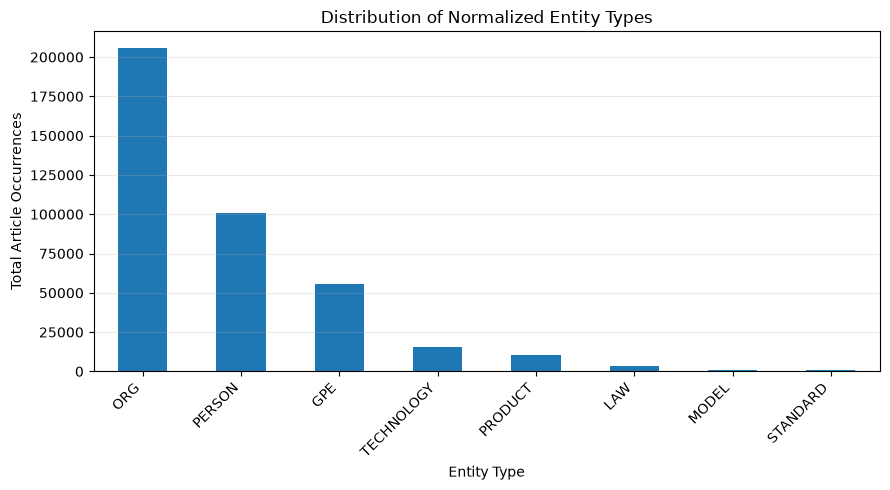

In [134]:
# Summarize article occurrences by normalized entity type
normalized_type_summary = (
    normalized_entity_frequency
    .groupby("Type")["Article Frequency"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

normalized_type_summary.plot(
    kind="bar"
)

plt.title("Distribution of Normalized Entity Types")
plt.xlabel("Entity Type")
plt.ylabel("Total Article Occurrences")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### Entity Extraction and Normalization Summary

Full-text Named Entity Recognition was applied to all 10,796 AI Governance-related articles, with at least one relevant entity identified in 10,792 articles.

The initial extraction produced a large and diverse entity set, but quality inspection revealed systematic inconsistencies in the labels assigned by the pretrained spaCy model. Frequently occurring organisations, AI technologies and model names were sometimes assigned to multiple entity types.

A conservative normalization layer was therefore applied to merge selected aliases, correct high-confidence classification errors and remove obvious extraction artefacts. The original NER output was retained separately to preserve traceability.

The normalized entity distribution is dominated by organisations and persons, followed by geopolitical entities. More specific AI-related categories such as technologies, products, models, laws and standards occur less frequently but provide additional structure for the topic-focused Knowledge Graph.

Remaining ambiguous entities were intentionally not globally reassigned where their interpretation depends on context. The normalized entities are therefore used as the basis for subsequent relation and co-occurrence analysis.

In [135]:
# Save the normalized entity output separately so it can be
# reused without repeating the normalization workflow.

NORMALIZED_ENTITY_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "governance_entities_normalized.pkl"
)

normalized_entity_data = governance_df[
    [
        "record_id",
        "entities_normalized"
    ]
].copy()

normalized_entity_data.to_pickle(
    NORMALIZED_ENTITY_PATH
)

print(
    f"Normalized entity data saved to: "
    f"{NORMALIZED_ENTITY_PATH}"
)

print(
    f"Articles saved: "
    f"{len(normalized_entity_data):,}"
)

print(
    f"File size: "
    f"{NORMALIZED_ENTITY_PATH.stat().st_size / (1024 ** 2):.1f} MB"
)

Normalized entity data saved to: C:\Users\dana1\Documents\CTL\data\processed\governance_entities_normalized.pkl
Articles saved: 10,796
File size: 7.4 MB


### Relation Extraction and Co-occurrence Analysis

The normalized entities are used to examine which entities occur together within the same AI Governance-related articles.

Co-occurrence provides a reproducible first representation of relationships between entities: two entities are connected when they are mentioned in the same article, while the number of articles in which they co-occur represents the strength of that connection.

Because the extraction contains a large number of rare entities, a minimum article-frequency threshold is determined before constructing the co-occurrence network. This reduces isolated or highly specific entities that would otherwise create a very large and noisy graph.

In [136]:
# Examine how different minimum article-frequency thresholds
# would affect the size of the Knowledge Graph.

frequency_thresholds = [2, 5, 10, 20, 50, 100]

threshold_summary = []

for threshold in frequency_thresholds:

    retained = normalized_entity_frequency.loc[
        normalized_entity_frequency["Article Frequency"] >= threshold
    ]

    threshold_summary.append({
        "Minimum Article Frequency": threshold,
        "Retained Entity-Label Combinations": len(retained),
        "Share of Entity-Label Combinations (%)": round(
            len(retained) / len(normalized_entity_frequency) * 100,
            2
        ),
        "Total Article Occurrences Retained": int(
            retained["Article Frequency"].sum()
        )
    })

threshold_summary = pd.DataFrame(threshold_summary)

display(threshold_summary)

,Minimum Article Frequency,Retained Entity-Label Combinations,Share of Entity-Label Combinations (%),Total Article Occurrences Retained
0,2,32888,21.01,269869
1,5,9081,5.80,211270
2,10,4078,2.61,179221
3,20,1904,1.22,149962
4,50,695,0.44,113681
5,100,306,0.20,87634


#### Frequency Threshold for Relation Extraction

Entity extraction produced a substantial long tail of entities that occur only in a small number of articles. Including all extracted entities would result in a very large and sparse co-occurrence network dominated by infrequent mentions.

A minimum article frequency of 20 is therefore applied for relation extraction. This retains 1,904 recurring entity-label combinations while substantially reducing the number of rare entities included in the graph.

The threshold is applied only to the relation and Knowledge Graph analysis; the complete normalized entity extraction remains preserved separately.

In [137]:
from itertools import combinations
from collections import Counter

# Minimum number of governance articles in which an entity must occur
MIN_ENTITY_FREQUENCY = 20

# Keep recurring entities for relation extraction
graph_entities = set(
    normalized_entity_frequency.loc[
        normalized_entity_frequency["Article Frequency"]
        >= MIN_ENTITY_FREQUENCY,
        ["Entity", "Type"]
    ].itertuples(index=False, name=None)
)

print(
    f"Entities retained for relation extraction: "
    f"{len(graph_entities):,}"
)


# Count how often two retained entities occur in the same article
cooccurrence_counter = Counter()

articles_with_multiple_entities = 0

for entities in governance_df["entities_normalized"]:

    retained_entities = sorted(
        set(entities) & graph_entities
    )

    if len(retained_entities) >= 2:
        articles_with_multiple_entities += 1

        for entity_a, entity_b in combinations(
            retained_entities,
            2
        ):
            cooccurrence_counter[
                (entity_a, entity_b)
            ] += 1


# Convert relationships into a DataFrame
cooccurrence_df = pd.DataFrame(
    [
        {
            "Entity_1": entity_a[0],
            "Type_1": entity_a[1],
            "Entity_2": entity_b[0],
            "Type_2": entity_b[1],
            "Cooccurrence_Count": count
        }
        for (entity_a, entity_b), count
        in cooccurrence_counter.items()
    ]
)

cooccurrence_df = (
    cooccurrence_df
    .sort_values(
        "Cooccurrence_Count",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    f"Articles containing at least two retained entities: "
    f"{articles_with_multiple_entities:,}"
)

print(
    f"Unique entity relationships: "
    f"{len(cooccurrence_df):,}"
)

print("\nStrongest co-occurring entity pairs:")

display(
    cooccurrence_df.head(30)
)

Entities retained for relation extraction: 1,904
Articles containing at least two retained entities: 10,576
Unique entity relationships: 451,241

Strongest co-occurring entity pairs:


,Entity_1,Type_1,Entity_2,Type_2,Cooccurrence_Count
0,Artificial Intelligence,TECHNOLOGY,United States,GPE,3114
1,Artificial Intelligence,TECHNOLOGY,Google,ORG,1584
2,Artificial Intelligence,TECHNOLOGY,OpenAI,ORG,1376
3,API,TECHNOLOGY,Artificial Intelligence,TECHNOLOGY,1225
4,China,GPE,United States,GPE,1186
5,Artificial Intelligence,TECHNOLOGY,Microsoft,ORG,1152
6,Trump,PERSON,United States,GPE,1001
7,Artificial Intelligence,TECHNOLOGY,China,GPE,987
8,Artificial Intelligence,TECHNOLOGY,Large Language Model,TECHNOLOGY,972
9,Artificial Intelligence,TECHNOLOGY,United Kingdom,GPE,952


In [138]:
# Additional high-confidence aliases identified during relation inspection
ADDITIONAL_ALIASES = {
    "Donald Trump": "Trump",
    "EU": "European Union"
}


def apply_additional_aliases(entity_list):

    cleaned_entities = []
    seen_entities = set()

    for entity_text, entity_type in entity_list:

        canonical_text = ADDITIONAL_ALIASES.get(
            entity_text,
            entity_text
        )

        # Preserve the already normalized type
        normalized_entity = (
            canonical_text,
            entity_type
        )

        if normalized_entity not in seen_entities:
            cleaned_entities.append(normalized_entity)
            seen_entities.add(normalized_entity)

    return cleaned_entities


governance_df["entities_normalized"] = (
    governance_df["entities_normalized"]
    .apply(apply_additional_aliases)
)

print("Additional high-confidence aliases applied.")

Additional high-confidence aliases applied.


In [139]:
normalized_entity_counter = Counter(
    entity
    for entities in governance_df["entities_normalized"]
    for entity in entities
)

normalized_entity_frequency = pd.DataFrame(
    [
        {
            "Entity": entity_text,
            "Type": entity_type,
            "Article Frequency": count
        }
        for (entity_text, entity_type), count
        in normalized_entity_counter.items()
    ]
).sort_values(
    "Article Frequency",
    ascending=False
).reset_index(drop=True)

In [140]:
# Examine how minimum co-occurrence thresholds affect network size

cooccurrence_thresholds = [2, 3, 5, 10, 20, 50, 100]

edge_threshold_summary = []

for threshold in cooccurrence_thresholds:

    retained_edges = cooccurrence_df.loc[
        cooccurrence_df["Cooccurrence_Count"] >= threshold
    ]

    retained_nodes = set(
        retained_edges["Entity_1"]
    ) | set(
        retained_edges["Entity_2"]
    )

    edge_threshold_summary.append({
        "Minimum Co-occurrence": threshold,
        "Retained Relationships": len(retained_edges),
        "Retained Entities": len(retained_nodes)
    })

edge_threshold_summary = pd.DataFrame(
    edge_threshold_summary
)

display(edge_threshold_summary)

,Minimum Co-occurrence,Retained Relationships,Retained Entities
0,2,232422,1824
1,3,151341,1824
2,5,85607,1824
3,10,38618,1824
4,20,17473,1610
5,50,3339,589
6,100,1082,261


In [141]:
display(normalized_entity_frequency.head(20))

,Entity,Type,Article Frequency
0,Artificial Intelligence,TECHNOLOGY,8899
1,United States,GPE,4022
2,Google,ORG,1740
3,OpenAI,ORG,1426
4,China,GPE,1370
5,API,TECHNOLOGY,1328
6,Microsoft,ORG,1258
7,United Kingdom,GPE,1214
8,Trump,PERSON,1187
9,Large Language Model,TECHNOLOGY,1003


In [142]:
# Save the final normalized entity data after the additional alias corrections

normalized_entity_data = governance_df[
    [
        "record_id",
        "entities_normalized"
    ]
].copy()

normalized_entity_data.to_pickle(
    NORMALIZED_ENTITY_PATH
)

print(
    f"Updated normalized entity data saved to: "
    f"{NORMALIZED_ENTITY_PATH}"
)

print(
    f"Articles saved: "
    f"{len(normalized_entity_data):,}"
)

print(
    f"File size: "
    f"{NORMALIZED_ENTITY_PATH.stat().st_size / (1024 ** 2):.1f} MB"
)

Updated normalized entity data saved to: C:\Users\dana1\Documents\CTL\data\processed\governance_entities_normalized.pkl
Articles saved: 10,796
File size: 7.4 MB


#### Co-occurrence Threshold Selection

The initial co-occurrence extraction produced a highly connected network, reflecting the large number of recurring entities in the governance-related corpus.

To reduce weak and potentially incidental relationships, different minimum co-occurrence thresholds were compared. A threshold of 50 shared articles was selected for the main Knowledge Graph. This reduces the network to 3,339 recurring relationships between 589 entities while retaining relationships that appear consistently across the corpus.

Lower-frequency relationships remain preserved in the complete co-occurrence data and can therefore be revisited if required.

In [143]:
# Retain recurring relationships for Knowledge Graph construction
MIN_COOCCURRENCE = 50

graph_edges = (
    cooccurrence_df.loc[
        cooccurrence_df["Cooccurrence_Count"]
        >= MIN_COOCCURRENCE
    ]
    .copy()
    .reset_index(drop=True)
)

graph_nodes = (
    set(graph_edges["Entity_1"])
    | set(graph_edges["Entity_2"])
)

print(f"Knowledge Graph entities: {len(graph_nodes):,}")
print(f"Knowledge Graph relationships: {len(graph_edges):,}")

display(graph_edges.head(30))

Knowledge Graph entities: 589
Knowledge Graph relationships: 3,339


,Entity_1,Type_1,Entity_2,Type_2,Cooccurrence_Count
0,Artificial Intelligence,TECHNOLOGY,United States,GPE,3114
1,Artificial Intelligence,TECHNOLOGY,Google,ORG,1584
2,Artificial Intelligence,TECHNOLOGY,OpenAI,ORG,1376
3,API,TECHNOLOGY,Artificial Intelligence,TECHNOLOGY,1225
4,China,GPE,United States,GPE,1186
5,Artificial Intelligence,TECHNOLOGY,Microsoft,ORG,1152
6,Trump,PERSON,United States,GPE,1001
7,Artificial Intelligence,TECHNOLOGY,China,GPE,987
8,Artificial Intelligence,TECHNOLOGY,Large Language Model,TECHNOLOGY,972
9,Artificial Intelligence,TECHNOLOGY,United Kingdom,GPE,952


In [144]:
from itertools import combinations
from collections import Counter

MIN_ENTITY_FREQUENCY = 20

# Use the FINAL normalized entity frequencies
graph_entities = set(
    normalized_entity_frequency.loc[
        normalized_entity_frequency["Article Frequency"]
        >= MIN_ENTITY_FREQUENCY,
        ["Entity", "Type"]
    ].itertuples(index=False, name=None)
)

cooccurrence_counter = Counter()
articles_with_multiple_entities = 0

for entities in governance_df["entities_normalized"]:

    retained_entities = sorted(
        set(entities) & graph_entities
    )

    if len(retained_entities) >= 2:
        articles_with_multiple_entities += 1

        for entity_a, entity_b in combinations(
            retained_entities,
            2
        ):
            cooccurrence_counter[
                (entity_a, entity_b)
            ] += 1


cooccurrence_df = pd.DataFrame(
    [
        {
            "Entity_1": entity_a[0],
            "Type_1": entity_a[1],
            "Entity_2": entity_b[0],
            "Type_2": entity_b[1],
            "Cooccurrence_Count": count
        }
        for (entity_a, entity_b), count
        in cooccurrence_counter.items()
    ]
).sort_values(
    "Cooccurrence_Count",
    ascending=False
).reset_index(drop=True)


print(
    f"Entities retained for relation extraction: "
    f"{len(graph_entities):,}"
)

print(
    f"Articles containing at least two retained entities: "
    f"{articles_with_multiple_entities:,}"
)

print(
    f"Unique entity relationships: "
    f"{len(cooccurrence_df):,}"
)

display(cooccurrence_df.head(30))

Entities retained for relation extraction: 1,902
Articles containing at least two retained entities: 10,576
Unique entity relationships: 449,324


,Entity_1,Type_1,Entity_2,Type_2,Cooccurrence_Count
0,Artificial Intelligence,TECHNOLOGY,United States,GPE,3114
1,Artificial Intelligence,TECHNOLOGY,Google,ORG,1584
2,Artificial Intelligence,TECHNOLOGY,OpenAI,ORG,1376
3,API,TECHNOLOGY,Artificial Intelligence,TECHNOLOGY,1225
4,China,GPE,United States,GPE,1186
5,Artificial Intelligence,TECHNOLOGY,Microsoft,ORG,1152
6,Trump,PERSON,United States,GPE,1089
7,Artificial Intelligence,TECHNOLOGY,China,GPE,987
8,Artificial Intelligence,TECHNOLOGY,Large Language Model,TECHNOLOGY,972
9,Artificial Intelligence,TECHNOLOGY,United Kingdom,GPE,952


In [145]:
MIN_COOCCURRENCE = 50

graph_edges = (
    cooccurrence_df.loc[
        cooccurrence_df["Cooccurrence_Count"]
        >= MIN_COOCCURRENCE
    ]
    .copy()
    .reset_index(drop=True)
)

graph_nodes = (
    set(graph_edges["Entity_1"])
    | set(graph_edges["Entity_2"])
)

print(
    f"Knowledge Graph entities: "
    f"{len(graph_nodes):,}"
)

print(
    f"Knowledge Graph relationships: "
    f"{len(graph_edges):,}"
)

display(graph_edges.head(30))

Knowledge Graph entities: 588
Knowledge Graph relationships: 3,267


,Entity_1,Type_1,Entity_2,Type_2,Cooccurrence_Count
0,Artificial Intelligence,TECHNOLOGY,United States,GPE,3114
1,Artificial Intelligence,TECHNOLOGY,Google,ORG,1584
2,Artificial Intelligence,TECHNOLOGY,OpenAI,ORG,1376
3,API,TECHNOLOGY,Artificial Intelligence,TECHNOLOGY,1225
4,China,GPE,United States,GPE,1186
5,Artificial Intelligence,TECHNOLOGY,Microsoft,ORG,1152
6,Trump,PERSON,United States,GPE,1089
7,Artificial Intelligence,TECHNOLOGY,China,GPE,987
8,Artificial Intelligence,TECHNOLOGY,Large Language Model,TECHNOLOGY,972
9,Artificial Intelligence,TECHNOLOGY,United Kingdom,GPE,952


#### Co-occurrence Matrix

A symmetric co-occurrence matrix is constructed from the filtered entity relationships. Each cell represents the number of governance-related articles in which two entities occur together.

Entity type is retained as part of the node identifier so that entities with the same surface name but different classifications are not unintentionally merged.

In [149]:
import numpy as np

# Create unique graph nodes using both entity name and entity type
graph_node_tuples = sorted(
    set(
        zip(
            graph_edges["Entity_1"],
            graph_edges["Type_1"]
        )
    )
    |
    set(
        zip(
            graph_edges["Entity_2"],
            graph_edges["Type_2"]
        )
    )
)

node_to_index = {
    node: index
    for index, node in enumerate(graph_node_tuples)
}

# Create the full symmetric co-occurrence matrix
matrix = np.zeros(
    (
        len(graph_node_tuples),
        len(graph_node_tuples)
    ),
    dtype=np.int32
)

for row in graph_edges.itertuples(index=False):

    node_1 = (row.Entity_1, row.Type_1)
    node_2 = (row.Entity_2, row.Type_2)

    i = node_to_index[node_1]
    j = node_to_index[node_2]

    weight = int(row.Cooccurrence_Count)

    matrix[i, j] = weight
    matrix[j, i] = weight


# Readable labels for display
node_labels = [
    f"{entity} [{entity_type}]"
    for entity, entity_type
    in graph_node_tuples
]

cooccurrence_matrix = pd.DataFrame(
    matrix,
    index=node_labels,
    columns=node_labels
)


print(
    f"Co-occurrence matrix dimensions: "
    f"{cooccurrence_matrix.shape}"
)

print(
    f"Relationships represented in matrix: "
    f"{np.count_nonzero(np.triu(matrix, k=1)):,}"
)


# Display a manageable matrix containing the 15 most frequent nodes
frequency_lookup = {
    (row.Entity, row.Type): row.Article_Frequency
    for row in normalized_entity_frequency.itertuples(index=False)
}

top_nodes = sorted(
    graph_node_tuples,
    key=lambda node: frequency_lookup.get(node, 0),
    reverse=True
)[:15]

top_node_labels = [
    f"{entity} [{entity_type}]"
    for entity, entity_type in top_nodes
]

display(
    cooccurrence_matrix.loc[
        top_node_labels,
        top_node_labels
    ]
)

Co-occurrence matrix dimensions: (600, 600)
Relationships represented in matrix: 3,267


AttributeError: 'Pandas' object has no attribute 'Article_Frequency'

In [150]:
# Display a manageable matrix containing the 15 most frequent graph nodes

# Create a lookup from (entity, type) to article frequency
frequency_lookup = (
    normalized_entity_frequency
    .set_index(["Entity", "Type"])["Article Frequency"]
    .to_dict()
)

# Select the 15 most frequently occurring nodes in the graph
top_nodes = sorted(
    graph_node_tuples,
    key=lambda node: frequency_lookup.get(node, 0),
    reverse=True
)[:15]

top_node_labels = [
    f"{entity} [{entity_type}]"
    for entity, entity_type in top_nodes
]

print("Top 15 entities included in the displayed co-occurrence matrix:")

display(
    pd.DataFrame(
        {
            "Entity": [node[0] for node in top_nodes],
            "Type": [node[1] for node in top_nodes],
            "Article Frequency": [
                frequency_lookup[node]
                for node in top_nodes
            ]
        }
    )
)

print("\nCo-occurrence matrix:")

display(
    cooccurrence_matrix.loc[
        top_node_labels,
        top_node_labels
    ]
)

Top 15 entities included in the displayed co-occurrence matrix:


,Entity,Type,Article Frequency
0,Artificial Intelligence,TECHNOLOGY,8899
1,United States,GPE,4022
2,Google,ORG,1740
3,OpenAI,ORG,1426
4,China,GPE,1370
5,API,TECHNOLOGY,1328
6,Microsoft,ORG,1258
7,United Kingdom,GPE,1214
8,Trump,PERSON,1187
9,Large Language Model,TECHNOLOGY,1003



Co-occurrence matrix:


,Artificial Intelligence [TECHNOLOGY],United States [GPE],Google [ORG],OpenAI [ORG],China [GPE],API [TECHNOLOGY],Microsoft [ORG],United Kingdom [GPE],Trump [PERSON],Large Language Model [TECHNOLOGY],European Union [ORG],Washington [GPE],California [GPE],Amazon [ORG],India [GPE]
Artificial Intelligence [TECHNOLOGY],0,3114,1584,1376,987,1225,1152,952,810,972,716,545,586,640,523
United States [GPE],3114,0,829,707,1186,236,593,744,1089,209,575,760,558,447,465
Google [ORG],1584,829,0,630,316,327,550,224,311,255,187,197,245,404,135
OpenAI [ORG],1376,707,630,0,292,288,467,160,330,305,142,155,193,237,98
China [GPE],987,1186,316,292,0,54,261,268,582,62,251,455,189,200,295
API [TECHNOLOGY],1225,236,327,288,54,0,252,87,0,363,91,0,0,88,0
Microsoft [ORG],1152,593,550,467,261,252,0,173,204,153,143,115,152,299,104
United Kingdom [GPE],952,744,224,160,268,87,173,0,153,52,299,86,113,132,185
Trump [PERSON],810,1089,311,330,582,0,204,153,0,0,163,502,308,199,141
Large Language Model [TECHNOLOGY],972,209,255,305,62,363,153,52,0,0,0,0,0,0,0


#### Co-occurrence Matrix

A symmetric co-occurrence matrix is constructed from the complete set of relationships between the recurring entities retained after entity-frequency filtering. Each cell represents the number of governance-related articles in which two entities occur together.

The matrix is kept unfiltered to preserve the observed co-occurrence frequencies. The stricter minimum co-occurrence threshold of 50 is applied separately during Knowledge Graph construction in order to reduce weak relationships in the network.

In [151]:
# Build the complete co-occurrence matrix before applying the graph edge threshold

import numpy as np

# All entity-type combinations retained after the entity-frequency threshold
cooccurrence_nodes = sorted(graph_entities)

node_to_index = {
    node: index
    for index, node in enumerate(cooccurrence_nodes)
}

matrix = np.zeros(
    (
        len(cooccurrence_nodes),
        len(cooccurrence_nodes)
    ),
    dtype=np.int32
)

# Use the COMPLETE co-occurrence data, not the >= 50 graph subset
for row in cooccurrence_df.itertuples(index=False):

    node_1 = (row.Entity_1, row.Type_1)
    node_2 = (row.Entity_2, row.Type_2)

    i = node_to_index[node_1]
    j = node_to_index[node_2]

    weight = int(row.Cooccurrence_Count)

    matrix[i, j] = weight
    matrix[j, i] = weight


node_labels = [
    f"{entity} [{entity_type}]"
    for entity, entity_type in cooccurrence_nodes
]

cooccurrence_matrix = pd.DataFrame(
    matrix,
    index=node_labels,
    columns=node_labels
)


print(
    f"Complete co-occurrence matrix dimensions: "
    f"{cooccurrence_matrix.shape}"
)

print(
    f"Relationships represented in matrix: "
    f"{np.count_nonzero(np.triu(matrix, k=1)):,}"
)


# Select the 15 most frequent entities for readable display
frequency_lookup = (
    normalized_entity_frequency
    .set_index(["Entity", "Type"])["Article Frequency"]
    .to_dict()
)

top_nodes = sorted(
    cooccurrence_nodes,
    key=lambda node: frequency_lookup.get(node, 0),
    reverse=True
)[:15]

top_node_labels = [
    f"{entity} [{entity_type}]"
    for entity, entity_type in top_nodes
]

display(
    cooccurrence_matrix.loc[
        top_node_labels,
        top_node_labels
    ]
)

Complete co-occurrence matrix dimensions: (1902, 1902)
Relationships represented in matrix: 449,324


,Artificial Intelligence [TECHNOLOGY],United States [GPE],Google [ORG],OpenAI [ORG],China [GPE],API [TECHNOLOGY],Microsoft [ORG],United Kingdom [GPE],Trump [PERSON],Large Language Model [TECHNOLOGY],European Union [ORG],Washington [GPE],California [GPE],Amazon [ORG],India [GPE]
Artificial Intelligence [TECHNOLOGY],0,3114,1584,1376,987,1225,1152,952,810,972,716,545,586,640,523
United States [GPE],3114,0,829,707,1186,236,593,744,1089,209,575,760,558,447,465
Google [ORG],1584,829,0,630,316,327,550,224,311,255,187,197,245,404,135
OpenAI [ORG],1376,707,630,0,292,288,467,160,330,305,142,155,193,237,98
China [GPE],987,1186,316,292,0,54,261,268,582,62,251,455,189,200,295
API [TECHNOLOGY],1225,236,327,288,54,0,252,87,17,363,91,10,47,88,43
Microsoft [ORG],1152,593,550,467,261,252,0,173,204,153,143,115,152,299,104
United Kingdom [GPE],952,744,224,160,268,87,173,0,153,52,299,86,113,132,185
Trump [PERSON],810,1089,311,330,582,17,204,153,0,42,163,502,308,199,141
Large Language Model [TECHNOLOGY],972,209,255,305,62,363,153,52,42,0,49,20,40,49,37


#### Co-occurrence Heatmap

To make the strongest relationships easier to interpret, the co-occurrence frequencies of the 15 most frequently mentioned entities are visualized as a heatmap.

The visualization uses the complete co-occurrence matrix and therefore includes relationships below the threshold later applied to the Knowledge Graph.

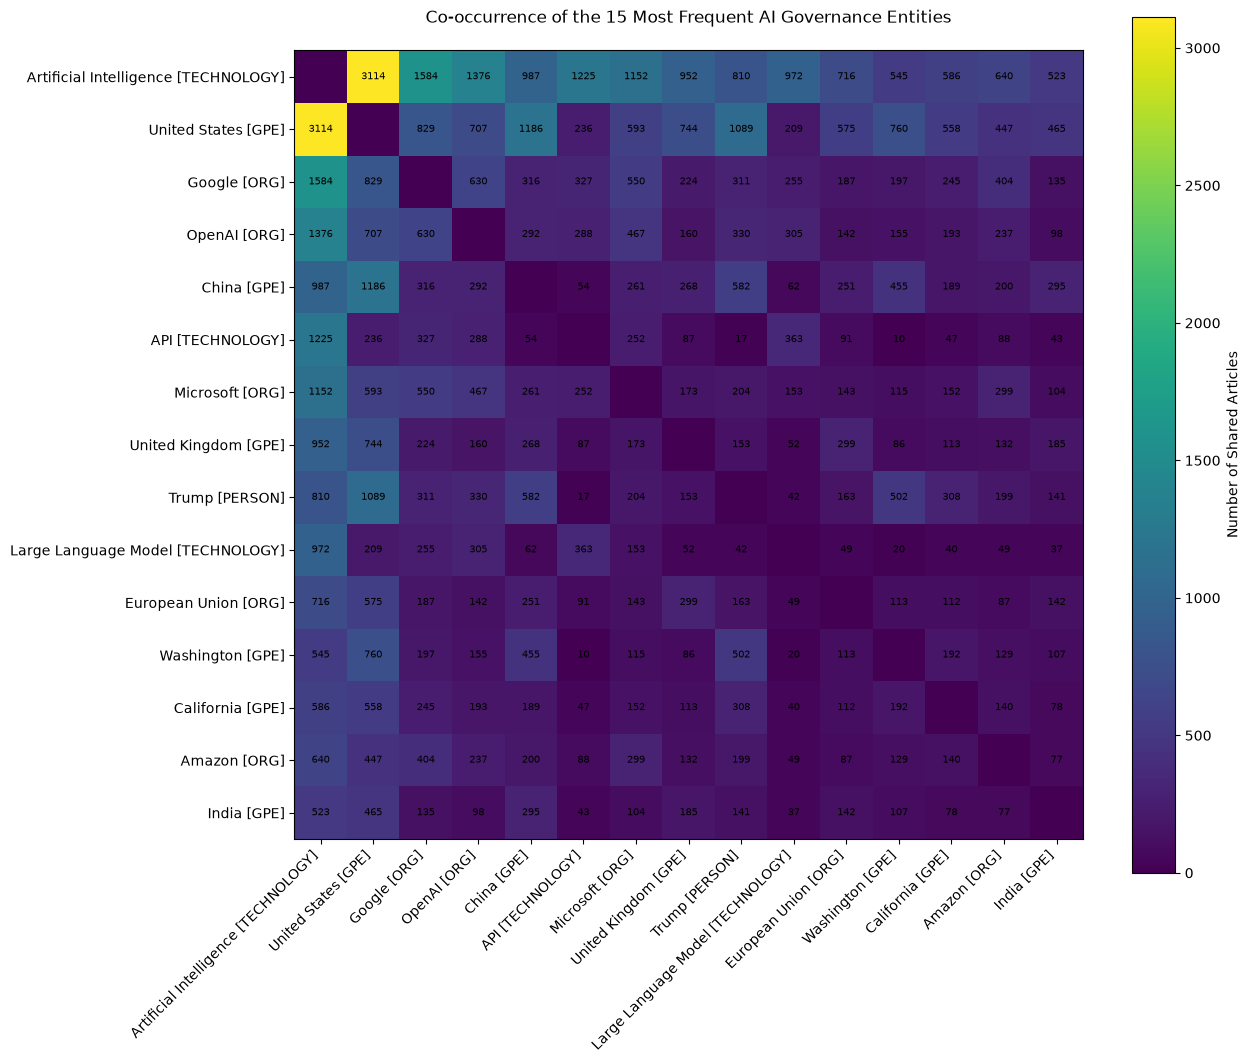

In [152]:
import matplotlib.pyplot as plt

# Use the same 15 high-frequency entities selected above
heatmap_data = cooccurrence_matrix.loc[
    top_node_labels,
    top_node_labels
]

fig, ax = plt.subplots(figsize=(13, 11))

image = ax.imshow(
    heatmap_data.values
)

# Axis labels
ax.set_xticks(range(len(top_node_labels)))
ax.set_yticks(range(len(top_node_labels)))

ax.set_xticklabels(
    top_node_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(top_node_labels)

ax.set_title(
    "Co-occurrence of the 15 Most Frequent AI Governance Entities",
    pad=20
)

# Show the actual number of shared articles in each cell
for i in range(len(top_node_labels)):
    for j in range(len(top_node_labels)):

        value = heatmap_data.iloc[i, j]

        if i != j:
            ax.text(
                j,
                i,
                f"{value}",
                ha="center",
                va="center",
                fontsize=7
            )

fig.colorbar(
    image,
    ax=ax,
    label="Number of Shared Articles"
)

plt.tight_layout()
plt.show()

#### Relation and Co-occurrence Summary

After applying the minimum entity-frequency threshold, 1,902 recurring entity-type combinations were retained for relation analysis. These entities formed 449,324 unique article-level co-occurrence relationships across 10,576 governance-related articles.

The co-occurrence matrix shows that the most prominent relationships centre around Artificial Intelligence, major technology organisations and geopolitical actors. Particularly strong associations include Artificial Intelligence with the United States, Google, OpenAI and Microsoft, as well as the United States with China and Trump.

Because the complete co-occurrence network is highly dense, a minimum relationship strength of 50 shared articles is used for Knowledge Graph construction. This retains 3,267 stronger recurring relationships while the complete co-occurrence information remains available separately.

Co-occurrence represents joint discussion within an article and should therefore be interpreted as an associative relationship rather than a causal or directional relationship.

### Knowledge Graph Construction and Analysis

In [153]:
# Save the completed relation-analysis outputs

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

COOCCURRENCE_PATH = (
    PROCESSED_DIR / "governance_cooccurrence_full.pkl"
)

GRAPH_EDGES_PATH = (
    PROCESSED_DIR / "governance_graph_edges.csv"
)

cooccurrence_df.to_pickle(COOCCURRENCE_PATH)

graph_edges.to_csv(
    GRAPH_EDGES_PATH,
    index=False
)

print(f"Full co-occurrence data saved to: {COOCCURRENCE_PATH}")
print(f"Filtered graph edges saved to: {GRAPH_EDGES_PATH}")

Full co-occurrence data saved to: C:\Users\dana1\Documents\CTL\data\processed\governance_cooccurrence_full.pkl
Filtered graph edges saved to: C:\Users\dana1\Documents\CTL\data\processed\governance_graph_edges.csv
